# EDA – Road Traffic Accidents in Germany 2025 (Unfallatlas)

## Setup
Import the libraries and load the dataset.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

unfall_raw = pd.read_csv("data/Unfallorte_2025.csv", sep=";")
unfall_raw.head()

/var/folders/rv/3zstxldn3b93ft9yj1vjb4j40000gn/T/ipykernel_1685/2965695596.py:4: DtypeWarning: Columns (0: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  unfall_raw = pd.read_csv("data/Unfallorte_2025.csv", sep=";")


,UIDENTSTLAE,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UJAHR,UMONAT,USTUNDE,UWOCHENTAG,UKATEGORIE,...,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstige,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84,PLST
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,...,1,0,0,0,0,"578658,645899999886751","5975441,506100000813603","10,197759334000068","53,921402971000077",1
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,...,0,0,0,0,0,"577747,035899999551475","5933250,982200000435114","10,173275287000024","53,542398901000070",1
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,...,1,0,0,0,0,"543500,281399999745190","5955819,687799999490380","9,659670060000053","53,749196565000034",1
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,...,1,1,0,0,0,"601362,065600000321865","6003468,873199999332428","10,552708229000075","54,169272189000083",1
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,...,0,0,0,0,0,"565151,556099999696016","6035315,988099999725819","10,005090446000054","54,461325762000058",1


In [3]:
unfall_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 25 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   UIDENTSTLAE         273007 non-null  object
 1   ULAND               273007 non-null  int64 
 2   UREGBEZ             273007 non-null  int64 
 3   UKREIS              273007 non-null  int64 
 4   UGEMEINDE           273007 non-null  int64 
 5   UJAHR               273007 non-null  int64 
 6   UMONAT              273007 non-null  int64 
 7   USTUNDE             273007 non-null  int64 
 8   UWOCHENTAG          273007 non-null  int64 
 9   UKATEGORIE          273007 non-null  int64 
 10  UART                273007 non-null  int64 
 11  UTYP1               273007 non-null  int64 
 12  ULICHTVERH          273007 non-null  int64 
 13  IstStrassenzustand  273007 non-null  int64 
 14  IstRad              273007 non-null  int64 
 15  IstPKW              273007 non-null  int64 
 16  IstFuss      

### Data types
- The dataset has **273,007 rows** and **25 columns**.
- There are **no missing values** (all columns have 273,007 non-null entries).
- 20 columns are **integers**, 1 is an **object** (UIDENTSTLAE), and 4 are **text** (LINREFX, LINREFY, XGCSWGS84, YGCSWGS84).

In [4]:
unfall_raw.columns

Index(['UIDENTSTLAE', 'ULAND', 'UREGBEZ', 'UKREIS', 'UGEMEINDE', 'UJAHR',
       'UMONAT', 'USTUNDE', 'UWOCHENTAG', 'UKATEGORIE', 'UART', 'UTYP1',
       'ULICHTVERH', 'IstStrassenzustand', 'IstRad', 'IstPKW', 'IstFuss',
       'IstKrad', 'IstGkfz', 'IstSonstige', 'LINREFX', 'LINREFY', 'XGCSWGS84',
       'YGCSWGS84', 'PLST'],
      dtype='str')

### Column descriptions
Source: official Unfallatlas data record description.

| Column | Description | Values |
|---|---|---|
| UIDENTSTLAE | Serial number (ID) of the accident | Unique identifier |
| ULAND | Federal state | 1 = Schleswig-Holstein, 2 = Hamburg, 3 = Niedersachsen, 4 = Bremen, 5 = Nordrhein-Westfalen, 6 = Hessen, 7 = Rheinland-Pfalz, 8 = Baden-Württemberg, 9 = Bayern, 10 = Saarland, 11 = Berlin, 12 = Brandenburg, 13 = Mecklenburg-Vorpommern, 14 = Sachsen, 15 = Sachsen-Anhalt, 16 = Thüringen |
| UREGBEZ | Administrative region (from the official municipality code) | Code |
| UKREIS | Administrative district | Code |
| UGEMEINDE | Municipality | Code |
| UJAHR | Year of the accident | 2025 |
| UMONAT | Month of the accident | 1–12 |
| USTUNDE | Hour of the accident | 0–23 |
| UWOCHENTAG | Day of the week | 1 = Sunday, 2 = Monday, 3 = Tuesday, 4 = Wednesday, 5 = Thursday, 6 = Friday, 7 = Saturday |
| UKATEGORIE | Accident category (most serious outcome) | 1 = persons killed, 2 = seriously injured, 3 = slightly injured |
| UART | Kind of accident | 1 = collision with a vehicle starting, stopping or stationary, 2 = with a vehicle moving ahead or waiting, 3 = with a vehicle moving laterally in the same direction, 4 = with an oncoming vehicle, 5 = with a vehicle turning into or crossing a road, 6 = between vehicle and pedestrian, 7 = with an obstacle in the carriageway, 8 = leaving the carriageway to the right, 9 = leaving the carriageway to the left, 0 = other kind |
| UTYP1 | Type of accident | 1 = driving accident, 2 = turning off the road, 3 = turning into a road or crossing it, 4 = crossing the road, 5 = involving stationary traffic, 6 = between vehicles moving along the carriageway, 7 = other |
| ULICHTVERH | Light conditions | 0 = daylight, 1 = twilight, 2 = darkness |
| IstStrassenzustand | Road surface condition | 0 = dry, 1 = wet/damp/slippery, 2 = slippery (winter) |
| IstRad | At least one bicycle involved | 0 = no, 1 = yes |
| IstPKW | At least one passenger car involved | 0 = no, 1 = yes |
| IstFuss | At least one pedestrian involved | 0 = no, 1 = yes |
| IstKrad | At least one motorcycle involved | 0 = no, 1 = yes |
| IstGkfz | At least one goods vehicle involved (over 3.5 t, semi-trailer, tractor, dangerous goods) | 0 = no, 1 = yes |
| IstSonstige | At least one other means of transport involved (e.g. bus, tram) | 0 = no, 1 = yes |
| LINREFX | X-coordinate of the accident location (UTM, EPSG:25832) | Metres |
| LINREFY | Y-coordinate of the accident location (UTM, EPSG:25832) | Metres |
| XGCSWGS84 | Longitude of the accident location (WGS84) | Decimal degrees |
| YGCSWGS84 | Latitude of the accident location (WGS84) | Decimal degrees |
| PLST | Plausibility check level of the location | 1 = regular check, 2 = advanced check for bicycle accidents |

### Renaming columns
The original German abbreviations are renamed to clear English names for easier reading.

In [5]:
acc = unfall_raw.rename(columns={
    "UIDENTSTLAE": "accident_id",
    "ULAND": "state",
    "UREGBEZ": "region",
    "UKREIS": "district",
    "UGEMEINDE": "municipality",
    "UJAHR": "year",
    "UMONAT": "month",
    "USTUNDE": "hour",
    "UWOCHENTAG": "weekday",
    "UKATEGORIE": "severity",
    "UART": "accident_kind",
    "UTYP1": "accident_type",
    "ULICHTVERH": "light",
    "IstStrassenzustand": "road_condition",
    "IstRad": "bicycle",
    "IstPKW": "car",
    "IstFuss": "pedestrian",
    "IstKrad": "motorcycle",
    "IstGkfz": "truck",
    "IstSonstige": "other_vehicle",
    "LINREFX": "utm_x",
    "LINREFY": "utm_y",
    "XGCSWGS84": "longitude",
    "YGCSWGS84": "latitude",
    "PLST": "location_check",
})
acc["severe"] = (acc["severity"] <= 2).astype(int)
acc.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,pedestrian,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,...,0,0,0,0,"578658,645899999886751","5975441,506100000813603","10,197759334000068","53,921402971000077",1,0
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,...,0,0,0,0,"577747,035899999551475","5933250,982200000435114","10,173275287000024","53,542398901000070",1,0
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,...,0,0,0,0,"543500,281399999745190","5955819,687799999490380","9,659670060000053","53,749196565000034",1,0
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,...,1,0,0,0,"601362,065600000321865","6003468,873199999332428","10,552708229000075","54,169272189000083",1,0
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,...,0,0,0,0,"565151,556099999696016","6035315,988099999725819","10,005090446000054","54,461325762000058",1,0


In [6]:
acc.info()

<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 26 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   accident_id     273007 non-null  object
 1   state           273007 non-null  int64 
 2   region          273007 non-null  int64 
 3   district        273007 non-null  int64 
 4   municipality    273007 non-null  int64 
 5   year            273007 non-null  int64 
 6   month           273007 non-null  int64 
 7   hour            273007 non-null  int64 
 8   weekday         273007 non-null  int64 
 9   severity        273007 non-null  int64 
 10  accident_kind   273007 non-null  int64 
 11  accident_type   273007 non-null  int64 
 12  light           273007 non-null  int64 
 13  road_condition  273007 non-null  int64 
 14  bicycle         273007 non-null  int64 
 15  car             273007 non-null  int64 
 16  pedestrian      273007 non-null  int64 
 17  motorcycle      273007 non-null  int64 


In [7]:
for acc_col in ["utm_x", "utm_y", "longitude", "latitude"]:
    acc[acc_col] = acc[acc_col].str.replace(",", ".").astype(float)
acc[["utm_x", "utm_y", "longitude", "latitude"]].describe()


,utm_x,utm_y,longitude,latitude
count,273007.000000,2.730070e+05,273007.000000,273007.000000
mean,549104.933113,5.636704e+06,9.701520,50.859482
std,151910.316367,1.970741e+05,2.173136,1.768320
min,280434.220500,5.240172e+06,5.867194,47.308169
25%,420808.683500,5.472213e+06,7.881520,49.393353
50%,531374.249000,5.658831e+06,9.449976,51.034495
75%,676738.976250,5.790455e+06,11.438347,52.246753
max,920210.344400,6.100338e+06,15.027292,55.048351


### Check of the coordinates
All 4 coordinate columns are now numeric, with no missing values.
- Longitude ranges from 5.87° to 15.03° and latitude from 47.31° to 55.05°, which matches Germany's borders.
- utm_x ranges from about 280 km to 920 km (about 220 km west to 420 km east of the 9° East line).
- utm_y ranges from about 5,240 km to 6,100 km north of the equator.
- No coordinates lie outside Germany, so there are no obvious location errors.

- All coordinates lie within Germany's bounding box (min/max check). The scatter plot below checks whether they also follow Germany's shape.

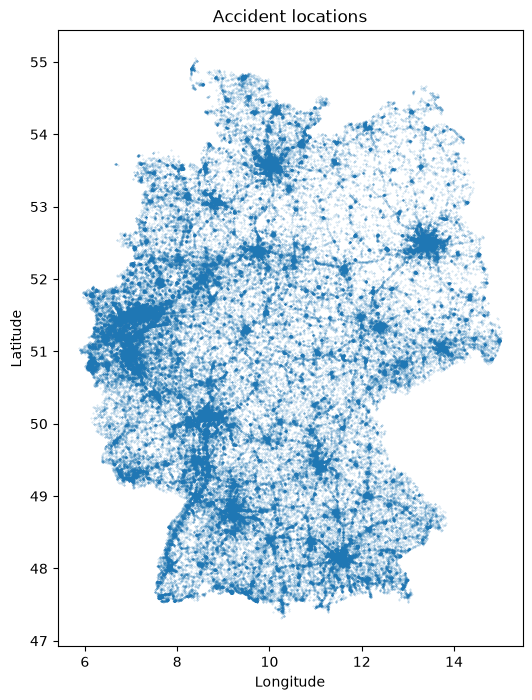

In [8]:
plt.figure(figsize=(6, 8))
plt.scatter(acc["longitude"], acc["latitude"], s=0.1, alpha=0.3)
plt.title("Accident locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

### Duplicates
Check if any accident appears more than once, as a full row or by its ID.

In [9]:
print("Duplicate rows:", acc.duplicated().sum())
print("Duplicate accident IDs:", acc["accident_id"].duplicated().sum())

Duplicate rows: 0
Duplicate accident IDs: 0


**Result:** 0 duplicate rows and 0 duplicate IDs. Every accident appears exactly once.

In [10]:
acc.columns

Index(['accident_id', 'state', 'region', 'district', 'municipality', 'year',
       'month', 'hour', 'weekday', 'severity', 'accident_kind',
       'accident_type', 'light', 'road_condition', 'bicycle', 'car',
       'pedestrian', 'motorcycle', 'truck', 'other_vehicle', 'utm_x', 'utm_y',
       'longitude', 'latitude', 'location_check', 'severe'],
      dtype='str')

In [11]:
acc["state"].describe()

count    273007.000000
mean          7.380708
std           3.639742
min           1.000000
25%           5.000000
50%           7.000000
75%           9.000000
max          16.000000
Name: state, dtype: float64

In [12]:
acc_state_names = {
    1: "Schleswig-Holstein", 2: "Hamburg", 3: "Niedersachsen", 4: "Bremen",
    5: "Nordrhein-Westfalen", 6: "Hessen", 7: "Rheinland-Pfalz", 8: "Baden-Württemberg",
    9: "Bayern", 10: "Saarland", 11: "Berlin", 12: "Brandenburg",
    13: "Mecklenburg-Vorpommern", 14: "Sachsen", 15: "Sachsen-Anhalt", 16: "Thüringen",
}
acc["state_name"] = acc["state"].map(acc_state_names)
acc["state_name"].value_counts()

state_name
Nordrhein-Westfalen       61521
Bayern                    46938
Baden-Württemberg         32042
Niedersachsen             24556
Hessen                    18578
Berlin                    13280
Rheinland-Pfalz           12816
Sachsen                   12724
Schleswig-Holstein        11645
Brandenburg                8459
Sachsen-Anhalt             7320
Hamburg                    7057
Thüringen                  5435
Mecklenburg-Vorpommern     4867
Saarland                   3194
Bremen                     2575
Name: count, dtype: int64

**Result:** All 16 states are included.
Nordrhein-Westfalen has the most accidents (61,521), followed by Bayern (46,938) and Baden-Württemberg (32,042).
Bremen has the fewest (2,575), followed by Saarland (3,194).
These are absolute numbers, so they don't show which state is more dangerous.

In [13]:
acc.head(5)

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe,state_name
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,...,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,0,Schleswig-Holstein
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,...,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,0,Schleswig-Holstein
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,...,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,0,Schleswig-Holstein
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,...,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,0,Schleswig-Holstein
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,...,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,0,Schleswig-Holstein


In [14]:
#acc["accident_id"].info()
#acc["state"].info()
#acc["region"].info()
#acc["region"].describe()
#acc.groupby("state_name")["region"].unique()
#acc[""].info()

In [15]:
acc_k = acc.copy()

acc_k_reg = acc_k["state"].astype(str) + "-" + acc_k["region"].astype(str)
acc_k_dis = acc_k_reg + "-" + acc_k["district"].astype(str)
acc_k_mun = acc_k_dis + "-" + acc_k["municipality"].astype(str)

acc_k["region"] = acc_k_reg
acc_k["district"] = acc_k_dis
acc_k["municipality"] = acc_k_mun

acc_k[["state_name", "region", "district", "municipality"]].head()

,state_name,region,district,municipality
0,Schleswig-Holstein,1-0,1-0-60,1-0-60-7
1,Schleswig-Holstein,1-0,1-0-62,1-0-62-53
2,Schleswig-Holstein,1-0,1-0-56,1-0-56-15
3,Schleswig-Holstein,1-0,1-0-55,1-0-55-28
4,Schleswig-Holstein,1-0,1-0-58,1-0-58-116


In [16]:
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe,state_name
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,6,3,...,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,0,Schleswig-Holstein
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,7,3,...,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,0,Schleswig-Holstein
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,7,3,...,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,0,Schleswig-Holstein
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,4,3,...,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,0,Schleswig-Holstein
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,3,3,...,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,0,Schleswig-Holstein


### New dataset `acc_k` with combined location keys
`acc_k` is a copy of `acc`. The columns region, district and municipality were changed,
because their original codes repeat across states (e.g. district 22 exists in several states).

Each value now contains its full path, separated by dashes:
**state → region → district → municipality**

| Column | Before | After | Meaning |
|---|---|---|---|
| region | 0 | `1-0` | state 1, region 0 |
| district | 60 | `1-0-60` | state 1, region 0, district 60 |
| municipality | 7 | `1-0-60-7` | state 1, region 0, district 60, municipality 7 |

**Check:** the number of unique keys matches the counts per state from the plot
(44 regions, 513 districts, 9,479 municipalities), so every key is unique.

In [17]:
acc_k.info()

<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 27 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   accident_id     273007 non-null  object 
 1   state           273007 non-null  int64  
 2   region          273007 non-null  str    
 3   district        273007 non-null  str    
 4   municipality    273007 non-null  str    
 5   year            273007 non-null  int64  
 6   month           273007 non-null  int64  
 7   hour            273007 non-null  int64  
 8   weekday         273007 non-null  int64  
 9   severity        273007 non-null  int64  
 10  accident_kind   273007 non-null  int64  
 11  accident_type   273007 non-null  int64  
 12  light           273007 non-null  int64  
 13  road_condition  273007 non-null  int64  
 14  bicycle         273007 non-null  int64  
 15  car             273007 non-null  int64  
 16  pedestrian      273007 non-null  int64  
 17  motorcycle      27300

In [18]:
acc_k["year_month"] = pd.to_datetime(acc_k["year"].astype(str) + "-" + acc_k["month"].astype(str), format="%Y-%m").dt.to_period("M")

acc_k[["year", "month", "year_month"]].head()

,year,month,year_month
0,2025,5,2025-05
1,2025,4,2025-04
2,2025,1,2025-01
3,2025,3,2025-03
4,2025,2,2025-02


In [19]:
acc_k.columns
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe,state_name,year_month
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,6,3,...,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,0,Schleswig-Holstein,2025-05
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,7,3,...,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,0,Schleswig-Holstein,2025-04
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,7,3,...,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,0,Schleswig-Holstein,2025-01
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,4,3,...,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,0,Schleswig-Holstein,2025-03
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,3,3,...,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,0,Schleswig-Holstein,2025-02


In [20]:
acc_k["weekday"] = acc_k["weekday"].map({
    1: "Sunday", 2: "Monday", 3: "Tuesday", 4: "Wednesday",
    5: "Thursday", 6: "Friday", 7: "Saturday",
})
acc_k["weekday"] = pd.Categorical(acc_k["weekday"], categories=[
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday",
], ordered=True)

acc_k["weekday"].value_counts(sort=False)

weekday
Monday       41378
Tuesday      42829
Wednesday    41881
Thursday     43288
Friday       43932
Saturday     34174
Sunday       25525
Name: count, dtype: int64

In [21]:
acc_part = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle"]

acc_k["participants"] = acc_k[acc_part].apply(lambda r: " + ".join(c for c in acc_part if r[c] == 1), axis=1)
acc_k["n_participant_types"] = acc_k[acc_part].sum(axis=1)

acc_k["participants"].value_counts().head(10)

participants
car                        92262
bicycle + car              43241
bicycle                    34334
car + motorcycle           19135
car + other_vehicle        19124
car + pedestrian           15501
motorcycle                 13375
other_vehicle               8118
car + truck                 7069
bicycle + other_vehicle     5558
Name: count, dtype: int64

In [22]:
acc_k["vulnerable"] = ((acc_k["bicycle"] == 1) | (acc_k["pedestrian"] == 1) | (acc_k["motorcycle"] == 1)).astype(int)
acc_k["single_type"] = (acc_k["n_participant_types"] == 1).astype(int)
acc_k["vulnerable_vs_vehicle"] = ((acc_k["vulnerable"] == 1) & ((acc_k["car"] == 1) | (acc_k["truck"] == 1) | (acc_k["other_vehicle"] == 1))).astype(int)

acc_k[["vulnerable", "single_type", "vulnerable_vs_vehicle"]].sum()

vulnerable               144353
single_type              149064
vulnerable_vs_vehicle     90995
dtype: int64

### New participant features
The six participant columns (bicycle, car, pedestrian, motorcycle, truck, other_vehicle) show who was involved.
One accident can involve several types, so new columns were created to describe the combinations:

| Column | Description |
|---|---|
| participants | All involved types as text, e.g. `bicycle + car` |
| n_participant_types | Number of different participant types involved (not number of people) |
| vulnerable | 1 = a bicycle, pedestrian or motorcycle was involved (road users without protection) |
| single_type | 1 = only one participant type was involved (e.g. a cyclist falling alone) |
| vulnerable_vs_vehicle | 1 = a vulnerable road user **and** a car, truck or other vehicle were involved |

**Limitation:** if more than two types are involved, the data does not show who collided with whom.

In [23]:
for acc_c in ["hour", "severity", "accident_kind", "accident_type", "light", "road_condition"]:
    print(acc_c, sorted(acc_k[acc_c].unique()))

hour [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
severity [np.int64(1), np.int64(2), np.int64(3)]
accident_kind [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
accident_type [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
light [np.int64(0), np.int64(1), np.int64(2)]
road_condition [np.int64(0), np.int64(1), np.int64(2)]


In [24]:
acc_k["severity"] = acc_k["severity"].map({
    1: "Accident with persons killed",
    2: "Accident with seriously injured",
    3: "Accident with slightly injured",
})
acc_k["accident_kind"] = acc_k["accident_kind"].map({
    0: "Accident of another kind",
    1: "Collision with another vehicle which starts, stops or is stationary",
    2: "Collision with another vehicle moving ahead or waiting",
    3: "Collision with another vehicle moving laterally in the same direction",
    4: "Collision with another oncoming vehicle",
    5: "Collision with another vehicle which turns into or crosses a road",
    6: "Collision between vehicle and pedestrian",
    7: "Collision with an obstacle in the carriageway",
    8: "Leaving the carriageway to the right",
    9: "Leaving the carriageway to the left",
})
acc_k["accident_type"] = acc_k["accident_type"].map({
    1: "Driving accident",
    2: "Accident caused by turning off the road",
    3: "Accident caused by turning into a road or by crossing it",
    4: "Accident caused by crossing the road",
    5: "Accident involving stationary",
    6: "Accident between vehicles moving along in carriageway",
    7: "Other accident",
})
acc_k["light"] = acc_k["light"].map({0: "daylight", 1: "twilight", 2: "darkness"})
acc_k["road_condition"] = acc_k["road_condition"].map({0: "dry", 1: "wet/damp/slippery", 2: "slippery (winter)"})

acc_k[["severity", "accident_kind", "accident_type", "light", "road_condition"]].isna().sum()

severity          0
accident_kind     0
accident_type     0
light             0
road_condition    0
dtype: int64

In [25]:
acc_k["accident_id"].map(type).value_counts()

accident_id
<class 'str'>    240239
<class 'int'>     32768
Name: count, dtype: int64

In [26]:
acc_k["accident_id"] = acc_k["accident_id"].astype(str).str.zfill(20)

acc_id_month = acc_k["accident_id"].str[4:6].astype(int)
acc_id_day = acc_k["accident_id"].str[6:8].astype(int)

print("ID lengths:", acc_k["accident_id"].str.len().unique())
print("ID month values:", sorted(acc_id_month.unique()))
print("ID day values:", sorted(acc_id_day.unique()))
print("ID month differs from month column:", (acc_id_month != acc_k["month"]).sum())

ID lengths: [20]
ID month values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
ID day values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31)]
ID month differs from month column: 10


In [27]:
acc_k[acc_id_month != acc_k["month"]][["accident_id", "state_name", "month", "weekday", "hour"]]

,accident_id,state_name,month,weekday,hour
97803,09250113005111028820,Bayern,2,Thursday,9
99687,09250117003119062870,Bayern,2,Monday,11
100346,09250310006309092460,Bayern,4,Thursday,22
103635,09250412006102136950,Bayern,5,Monday,15
104516,09250425001170144840,Bayern,5,Sunday,21
107210,09250528005509256820,Bayern,6,Saturday,16
118642,09251019001409494090,Bayern,11,Wednesday,10
215688,09250221004105092400,Bayern,3,Friday,21
221369,09250519005515319100,Bayern,6,Thursday,21
225116,09250629005533263540,Bayern,7,Tuesday,14


### Finding: the accident ID contains the date
The data description does not document the structure of `accident_id`, but checking all rows shows:

**ID structure (20 characters):** 2-digit state + `25` (year) + 2-digit month + 2-digit day + further digits
Example: `01250509171013352025` → state 01, year 2025, month 05, day 09

**Loading problem:** 17,128 IDs (Schleswig-Holstein, Hamburg, Niedersachsen) were read as numbers,
so their leading zero was lost (19 instead of 20 characters). This was fixed with `zfill(20)`.

**Checks on all 273,007 IDs:**
- All IDs have 20 characters
- Month part contains only 1–12, day part only 1–31
- The ID month matches the `month` column in all rows except **10**

**The 10 mismatches:** all from **Bayern**, and in every case the `month` column is exactly one month
later than the ID month. Combining the ID **day** with the `month` column gives a date whose weekday
matches the `weekday` column in all 10 rows. So the `month` and `weekday` columns are consistent,
and the ID month is off by one in these rows.

**New column `date`:** built from `year`, the `month` column and the **day from the ID**.
Weekday check of the new date against the `weekday` column: ___ mismatches

In [28]:
acc_k["date"] = pd.to_datetime(dict(year=acc_k["year"], month=acc_k["month"], day=acc_id_day))

print("Weekday mismatch:", (acc_k["date"].dt.day_name() != acc_k["weekday"].astype(str)).sum())
acc_k[["accident_id", "month", "weekday", "date"]].head()

Weekday mismatch: 8


,accident_id,month,weekday,date
0,01250509171013352025,5,Friday,2025-05-09
1,01250405161013752025,4,Saturday,2025-04-05
2,01250118171013142025,1,Saturday,2025-01-18
3,01250326152013912025,3,Wednesday,2025-03-26
4,01250225145013362025,2,Tuesday,2025-02-25


In [29]:
acc_k.head(10)

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,location_check,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25
5,01250214145013972025,1,1-0,1-0-58,1-0-58-135,2025,2,10,Friday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-02,car,1,0,1,0,2025-02-14
6,01250213161013652025,1,1-0,1-0-53,1-0-53-41,2025,2,11,Thursday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-02,bicycle + car,2,1,0,1,2025-02-13
7,01250520171013162025,1,1-0,1-0-60,1-0-60-2,2025,5,16,Tuesday,Accident with seriously injured,...,1,1,Schleswig-Holstein,2025-05,car + other_vehicle,2,0,0,0,2025-05-20
8,01250120125013112025,1,1-0,1-0-1,1-0-1-0,2025,1,15,Monday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-01,bicycle,1,1,1,0,2025-01-20
9,01250201105132612025,1,1-0,1-0-55,1-0-55-4,2025,2,15,Saturday,Accident with slightly injured,...,1,0,Schleswig-Holstein,2025-02,car,1,0,1,0,2025-02-01


In [30]:
acc_wd = acc_k[acc_k["date"].dt.day_name() != acc_k["weekday"].astype(str)].copy()
acc_wd["date_weekday"] = acc_wd["date"].dt.day_name()
acc_wd[["accident_id", "state_name", "date", "date_weekday", "weekday", "hour"]]

,accident_id,state_name,date,date_weekday,weekday,hour
105094,09250421004109128620,Bayern,2025-04-21,Monday,Saturday,15
110686,09250705003219291490,Bayern,2025-07-05,Saturday,Sunday,2
117122,09251025004109540040,Bayern,2025-10-25,Saturday,Friday,22
216339,09250126002219028530,Bayern,2025-01-26,Sunday,Wednesday,6
216359,09250129008571022830,Bayern,2025-01-29,Wednesday,Tuesday,7
226068,09250703008523271550,Bayern,2025-07-03,Thursday,Wednesday,10
227261,09250715008512385640,Bayern,2025-07-15,Tuesday,Sunday,17
252545,13250222314300690225,Mecklenburg-Vorpommern,2025-02-22,Saturday,Sunday,4


Weekday check: 8 rows (7 Bayern, 1 Mecklenburg-Vorpommern) have a date whose weekday does not match the weekday column, with no consistent pattern. Their date was set to missing; all other 272,999 dates are verified.

In [31]:
acc_k.loc[acc_wd.index, "date"] = pd.NaT

print("Missing dates:", acc_k["date"].isna().sum())
print("Weekday mismatch:", (acc_k["date"].dt.day_name() != acc_k["weekday"].astype(str))[acc_k["date"].notna()].sum())

Missing dates: 8
Weekday mismatch: 0


In [32]:
acc_k["date_check"] = "ok"
acc_k.loc[acc_id_month != acc_k["month"], "date_check"] = "month corrected"
acc_k.loc[acc_wd.index, "date_check"] = "date missing"

acc_k["date_check"].value_counts()

date_check
ok                 272989
month corrected        10
date missing            8
Name: count, dtype: int64

### Finding: the accident ID contains the date
The data description does not document the structure of `accident_id`, but checking all rows shows:

**ID structure (20 characters):** 2-digit state + `25` (year) + 2-digit month + 2-digit day + further digits
Example: `01250509171013352025` → state 01, year 2025, month 05, day 09

**Loading problem:** 17,128 IDs (Schleswig-Holstein, Hamburg, Niedersachsen) were read as numbers,
so their leading zero was lost (19 instead of 20 characters). This was fixed with `zfill(20)`.

**Checks on all 273,007 IDs:**
- All IDs have 20 characters
- Month part contains only 1–12, day part only 1–31
- The ID month matches the `month` column in all rows except 10

**New column `date`:** built from `year`, the `month` column and the **day from the ID**,
then checked against the `weekday` column.

**New column `date_check`:**

| Status | Rows | Meaning |
|---|---|---|
| ok | 272,989 | Date from the ID matches month and weekday |
| month corrected | 10 | ID month was one month too early (all Bayern); month taken from the `month` column, the weekday then matches |
| date missing | 8 | Weekday contradicts the date with no consistent pattern (7 Bayern, 1 Mecklenburg-Vorpommern); date set to missing |

These 18 rows are data inconsistencies, not outliers. They are kept, because all other columns are still valid.

In [33]:
acc_k.loc[acc_k["date_check"] != "ok", "date"] = pd.NaT
acc_k.loc[acc_k["date_check"] == "month corrected", "date_check"] = "date missing (month mismatch)"
acc_k.loc[acc_k["date_check"] == "date missing", "date_check"] = "date missing (weekday mismatch)"

print("Missing dates:", acc_k["date"].isna().sum())
acc_k["date_check"].value_counts()

Missing dates: 18


date_check
ok                                 272989
date missing (month mismatch)          10
date missing (weekday mismatch)         8
Name: count, dtype: int64

| Status | Rows | Meaning |
|---|---|---|
| ok | 272,989 | Date from the ID matches month and weekday |
| date missing (month mismatch) | 10 | ID month contradicts the `month` column (all Bayern) |
| date missing (weekday mismatch) | 8 | ID day contradicts the `weekday` column (7 Bayern, 1 Mecklenburg-Vorpommern) |

The date of these 18 rows was set to missing instead of guessed. The rows are kept, because all other columns are still valid.

In [34]:
acc_k[acc_k["date"].isna()][["accident_id", "date", "date_check"]]

,accident_id,date,date_check
97803,09250113005111028820,NaT,date missing (month mismatch)
99687,09250117003119062870,NaT,date missing (month mismatch)
100346,09250310006309092460,NaT,date missing (month mismatch)
103635,09250412006102136950,NaT,date missing (month mismatch)
104516,09250425001170144840,NaT,date missing (month mismatch)
105094,09250421004109128620,NaT,date missing (weekday mismatch)
107210,09250528005509256820,NaT,date missing (month mismatch)
110686,09250705003219291490,NaT,date missing (weekday mismatch)
117122,09251025004109540040,NaT,date missing (weekday mismatch)
118642,09251019001409494090,NaT,date missing (month mismatch)


In [35]:
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok


In [36]:
for acc_c in ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle"]:
    print(acc_c, sorted(acc_k[acc_c].unique()))

bicycle [np.int64(0), np.int64(1)]
car [np.int64(0), np.int64(1)]
pedestrian [np.int64(0), np.int64(1)]
motorcycle [np.int64(0), np.int64(1)]
truck [np.int64(0), np.int64(1)]
other_vehicle [np.int64(0), np.int64(1)]


### Check of `location_check`
`location_check` (original: PLST) shows how the location of each accident was verified by the statistical offices
(source: official data description):
- **1** = successful location check according to the regular procedure
- **2** = successful location check according to an advanced procedure for accidents involving bicycles

**What is checked:**
1. The column contains only the values 1 and 2.
2. Level 2 only appears in accidents with a bicycle involved (`bicycle = 1`), otherwise the two columns contradict each other.

The column describes the verification of the location, not the accident itself, so it is not used as a feature for the model.

In [37]:
print(acc_k["location_check"].value_counts())
print("Check 2 without bicycle:", ((acc_k["location_check"] == 2) & (acc_k["bicycle"] == 0)).sum())

location_check
1    265616
2      7391
Name: count, dtype: int64
Check 2 without bicycle: 0


**Result:** Only the values 1 (265,616 accidents) and 2 (7,391 accidents) appear.
All 7,391 accidents with level 2 involve a bicycle, so the column is consistent with `bicycle`.

In [38]:
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok


## Final dataset `acc_k`
**273,007 accidents, 35 columns.** All original columns were renamed, checked against the official
data description, and codes were replaced by their official names.

| Group | Columns |
|---|---|
| ID | accident_id (20 characters, leading zeros restored) |
| Location (keys) | state, state_name, region, district, municipality (e.g. `1-0-60-7`) |
| Coordinates | utm_x, utm_y, longitude, latitude |
| Time | year, month, hour, weekday, year_month, date, date_check |
| Accident | severity, accident_kind, accident_type |
| Conditions | light, road_condition |
| Participants | bicycle, car, pedestrian, motorcycle, truck, other_vehicle |
| New participant features | participants, n_participant_types, vulnerable, single_type, vulnerable_vs_vehicle |
| Target | severe (1 = killed or seriously injured, 0 = slightly injured) |
| Location verification | location_check |

**Data quality:** no duplicates, no missing values except 18 dates set to missing (see `date_check`).

In [39]:
acc_sev = acc_k["severity"].value_counts().to_frame("count")
acc_sev["percent"] = (acc_sev["count"] / len(acc_k) * 100).round(1)
acc_sev

,count,percent
severity,,
Accident with slightly injured,230100,84.3
Accident with seriously injured,40430,14.8
Accident with persons killed,2477,0.9


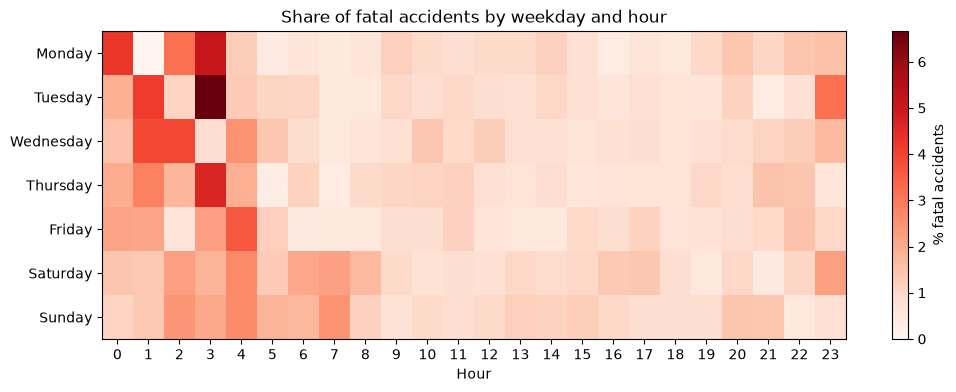

In [40]:
acc_k["killed"] = (acc_k["severity"] == "Accident with persons killed").astype(int)
acc_heat = acc_k.pivot_table(index="weekday", columns="hour", values="killed", aggfunc="mean", observed=True)

plt.figure(figsize=(12, 4))
plt.imshow(acc_heat * 100, aspect="auto", cmap="Reds")
plt.colorbar(label="% fatal accidents")
plt.yticks(range(7), acc_heat.index)
plt.xticks(range(24), acc_heat.columns)
plt.xlabel("Hour")
plt.title("Share of fatal accidents by weekday and hour")
plt.show()

In [41]:
print(acc_k.describe(include="number").T)
acc_k.describe(exclude="number").T

                          count          mean            std           min  \
state                  273007.0  7.380708e+00       3.639742  1.000000e+00   
year                   273007.0  2.025000e+03       0.000000  2.025000e+03   
month                  273007.0  6.641009e+00       3.180641  1.000000e+00   
hour                   273007.0  1.343959e+01       4.780902  0.000000e+00   
bicycle                273007.0  3.279073e-01       0.469452  0.000000e+00   
car                    273007.0  7.237836e-01       0.447126  0.000000e+00   
pedestrian             273007.0  8.804536e-02       0.283361  0.000000e+00   
motorcycle             273007.0  1.344215e-01       0.341105  0.000000e+00   
truck                  273007.0  3.977554e-02       0.195432  0.000000e+00   
other_vehicle          273007.0  1.449487e-01       0.352050  0.000000e+00   
utm_x                  273007.0  5.491049e+05  151910.316367  2.804342e+05   
utm_y                  273007.0  5.636704e+06  197074.118960  5.

,count,unique,top,freq,mean,min,25%,50%,75%,max
accident_id,273007,273007,01250509171013352025,1,NaN,NaN,NaN,NaN,NaN,NaN
region,273007,44,5-1,18031,NaN,NaN,NaN,NaN,NaN,NaN
district,273007,513,9-1-62,5264,NaN,NaN,NaN,NaN,NaN,NaN
municipality,273007,9479,9-1-62-0,5264,NaN,NaN,NaN,NaN,NaN,NaN
weekday,273007,7,Friday,43932,NaN,NaN,NaN,NaN,NaN,NaN
severity,273007,3,Accident with slightly injured,230100,NaN,NaN,NaN,NaN,NaN,NaN
accident_kind,273007,10,Collision with another vehicle which turns int...,72677,NaN,NaN,NaN,NaN,NaN,NaN
accident_type,273007,7,Accident between vehicles moving along in carr...,64220,NaN,NaN,NaN,NaN,NaN,NaN
light,273007,3,daylight,208489,NaN,NaN,NaN,NaN,NaN,NaN
road_condition,273007,3,dry,212665,NaN,NaN,NaN,NaN,NaN,NaN


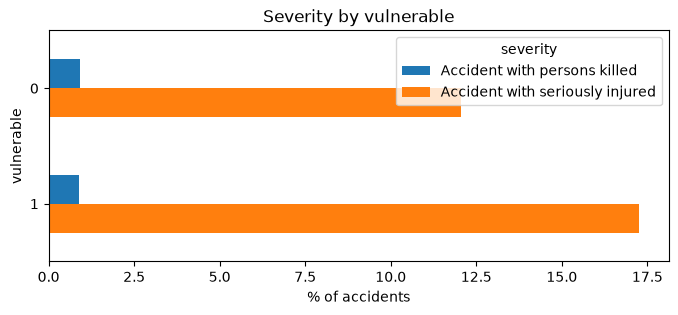

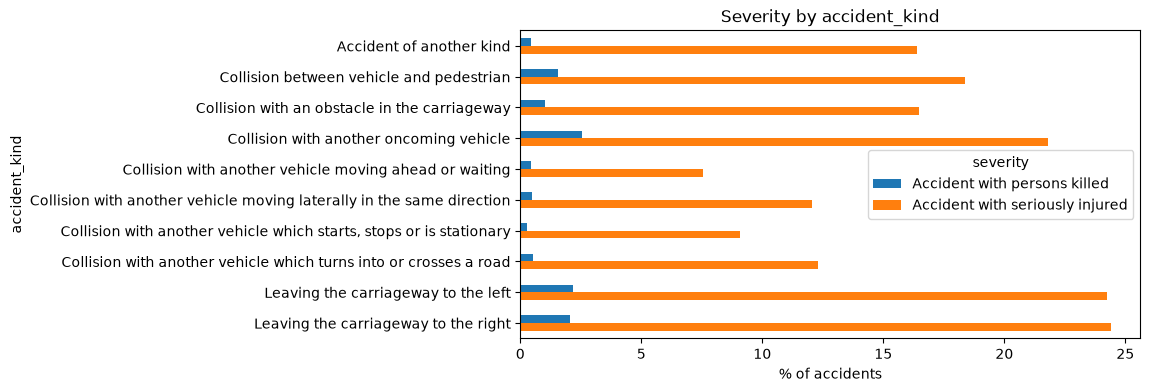

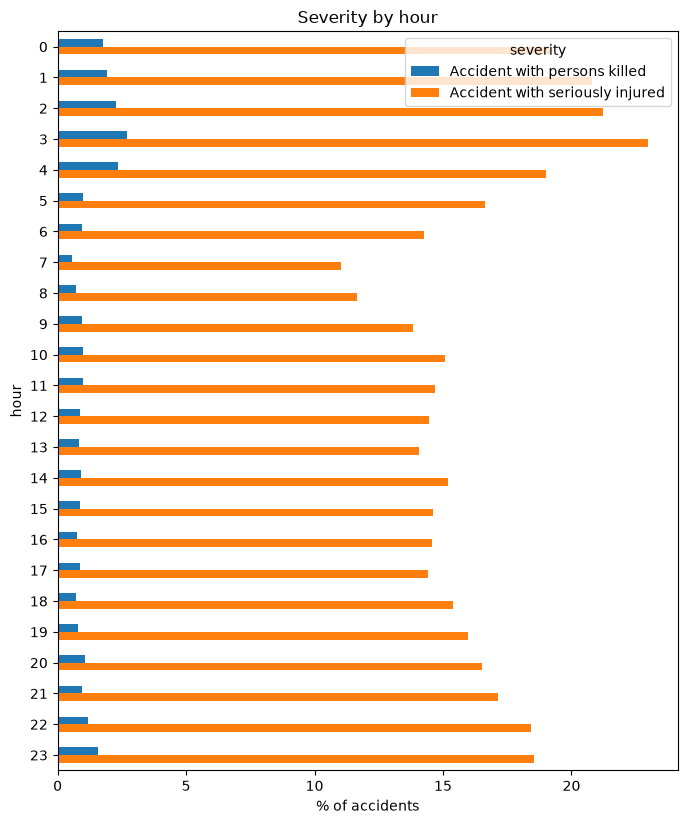

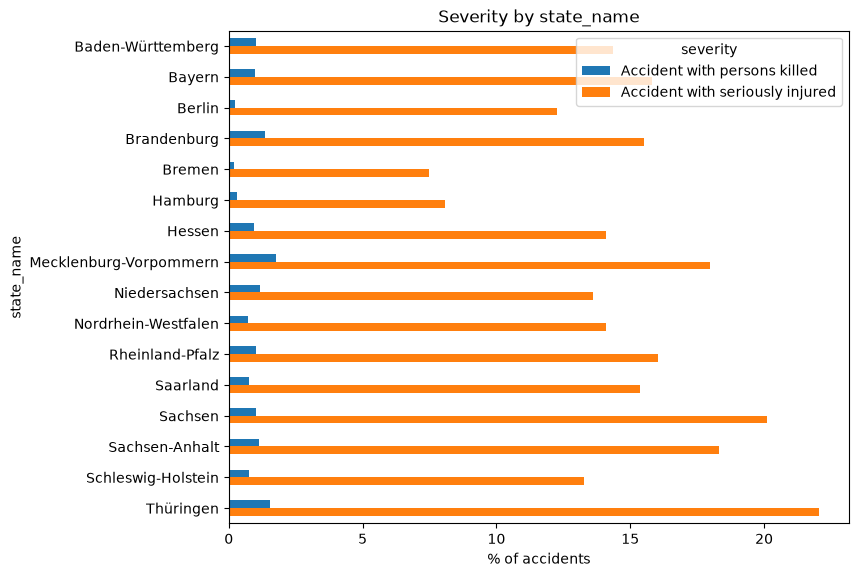

In [42]:
acc_sev_order = ["Accident with persons killed", "Accident with seriously injured", "Accident with slightly injured"]

def acc_sev_plot(acc_col):
    acc_tab = pd.crosstab(acc_k[acc_col], acc_k["severity"], normalize="index")[acc_sev_order] * 100
    acc_tab[acc_sev_order[:2]].plot(kind="barh", figsize=(8, max(3, len(acc_tab) * 0.4)))
    plt.title(f"Severity by {acc_col}")
    plt.xlabel("% of accidents")
    plt.gca().invert_yaxis()
    plt.show()

for acc_col in ["vulnerable", "accident_kind", "hour", "state_name"]:
    acc_sev_plot(acc_col)

In [43]:
acc_explore_cols = ["participants", "vulnerable", "vulnerable_vs_vehicle", "single_type",
                    "accident_kind", "accident_type", "light", "road_condition",
                    "hour", "weekday", "month", "state_name"]

acc_rows = []
for acc_col in acc_explore_cols:
    acc_grp = acc_k.groupby(acc_col, observed=True)["severity"]
    for acc_val, acc_s in acc_grp:
        if len(acc_s) >= 500:
            acc_rows.append({
                "column": acc_col, "value": acc_val, "accidents": len(acc_s),
                "% killed": round((acc_s == "Accident with persons killed").mean() * 100, 2),
                "% seriously": round((acc_s == "Accident with seriously injured").mean() * 100, 2),
            })

acc_results = pd.DataFrame(acc_rows).sort_values("% killed", ascending=False)
acc_results.head(15)

,column,value,accidents,% killed,% seriously
5,participants,bicycle + truck,787,4.07,24.90
17,participants,truck + other_vehicle,748,3.74,19.92
16,participants,truck,975,3.18,23.79
50,hour,3,1288,2.72,22.98
10,participants,car + truck,7069,2.60,14.46
27,accident_kind,Collision with another oncoming vehicle,18985,2.54,21.81
51,hour,4,1395,2.37,19.00
49,hour,2,1498,2.27,21.23
15,participants,pedestrian + other_vehicle,3237,2.26,15.45
32,accident_kind,Leaving the carriageway to the left,12947,2.19,24.23


In [44]:
acc_results[acc_results["column"].isin(["road_condition", "light"])].sort_values(["column", "% killed"], ascending=[True, False])

,column,value,accidents,% killed,% seriously
41,light,darkness,50553,1.23,16.10
43,light,twilight,13965,0.84,14.52
42,light,daylight,208489,0.83,14.52
46,road_condition,wet/damp/slippery,54919,0.95,13.72
44,road_condition,dry,212665,0.90,15.12
45,road_condition,slippery (winter),5423,0.53,13.79


In [45]:
acc_k.columns

Index(['accident_id', 'state', 'region', 'district', 'municipality', 'year',
       'month', 'hour', 'weekday', 'severity', 'accident_kind',
       'accident_type', 'light', 'road_condition', 'bicycle', 'car',
       'pedestrian', 'motorcycle', 'truck', 'other_vehicle', 'utm_x', 'utm_y',
       'longitude', 'latitude', 'location_check', 'severe', 'state_name',
       'year_month', 'participants', 'n_participant_types', 'vulnerable',
       'single_type', 'vulnerable_vs_vehicle', 'date', 'date_check', 'killed'],
      dtype='str')

Accidents in Dresden: 2154
Average location: 51.053 13.75
Share with bicycle: 57.1 %
severity
Accident with slightly injured     84.7
Accident with seriously injured    14.9
Accident with persons killed        0.4
Name: proportion, dtype: float64


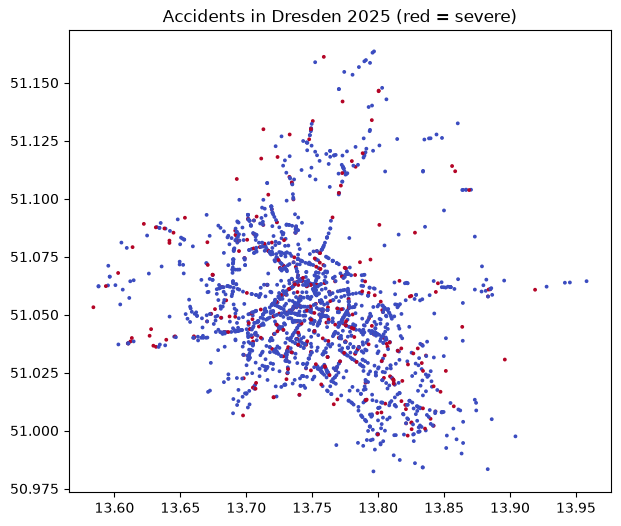

In [46]:
acc_dd = acc_k[acc_k["district"] == "14-6-12"].copy()

print("Accidents in Dresden:", len(acc_dd))
print("Average location:", acc_dd["latitude"].mean().round(3), acc_dd["longitude"].mean().round(3))
print("Share with bicycle:", round(acc_dd["bicycle"].mean() * 100, 1), "%")
print(acc_dd["severity"].value_counts(normalize=True).mul(100).round(1))

plt.figure(figsize=(7, 6))
plt.scatter(acc_dd["longitude"], acc_dd["latitude"], c=acc_dd["severe"], cmap="coolwarm", s=3)
plt.title("Accidents in Dresden 2025 (red = severe)")
plt.show()

In [47]:
def acc_dd_compare(acc_col, acc_top=None):
    acc_t = pd.DataFrame({
        "DD accidents": acc_dd[acc_col].value_counts(),
        "DD %": (acc_dd[acc_col].value_counts(normalize=True) * 100).round(1),
        "Germany %": (acc_k[acc_col].value_counts(normalize=True) * 100).round(1),
        "DD % severe": (acc_dd.groupby(acc_col, observed=True)["severe"].mean() * 100).round(1),
    }).dropna(subset=["DD accidents"]).sort_values("DD accidents", ascending=False)
    print(f"\n===== {acc_col} =====")
    display(acc_t.head(acc_top) if acc_top else acc_t)

print("Accidents in Dresden:", len(acc_dd))
print("Severe:", acc_dd["severe"].sum(), f"({acc_dd['severe'].mean() * 100:.1f} %, Germany {acc_k['severe'].mean() * 100:.1f} %)")
print("Killed:", (acc_dd["severity"] == "Accident with persons killed").sum())

acc_part = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle", "vulnerable", "single_type", "vulnerable_vs_vehicle"]
print("\n===== participants involved (% of accidents) =====")
display(pd.DataFrame({"DD %": (acc_dd[acc_part].mean() * 100).round(1),
                      "Germany %": (acc_k[acc_part].mean() * 100).round(1),
                      "DD % severe if involved": [(acc_dd[acc_dd[c] == 1]["severe"].mean() * 100).round(1) for c in acc_part]}))

acc_dd_compare("participants", 10)
for acc_col in ["accident_kind", "accident_type", "light", "road_condition", "weekday", "month", "hour"]:
    acc_dd_compare(acc_col)

Accidents in Dresden: 2154
Severe: 329 (15.3 %, Germany 15.7 %)
Killed: 9

===== participants involved (% of accidents) =====


,DD %,Germany %,DD % severe if involved
bicycle,57.1,32.8,13.6
car,61.1,72.4,13.3
pedestrian,11.3,8.8,26.2
motorcycle,9.9,13.4,19.6
truck,2.5,4.0,20.4
other_vehicle,12.9,14.5,18.3
vulnerable,74.2,52.9,16.0
single_type,45.4,54.6,15.3
vulnerable_vs_vehicle,43.4,33.3,14.6



===== participants =====


,DD accidents,DD %,Germany %,DD % severe
participants,,,,
bicycle + car,538.0,25.0,15.8,8.4
bicycle,527.0,24.5,12.6,17.5
car,358.0,16.6,33.8,11.2
car + motorcycle,139.0,6.5,7.0,18.0
car + pedestrian,123.0,5.7,5.7,30.9
car + other_vehicle,122.0,5.7,7.0,16.4
bicycle + pedestrian,77.0,3.6,1.5,18.2
bicycle + other_vehicle,67.0,3.1,2.0,19.4
motorcycle,51.0,2.4,4.9,21.6



===== accident_kind =====


...

,DD accidents,DD %,Germany %,DD % severe
weekday,,,,
Thursday,390,18.1,15.9,11.5
Tuesday,380,17.6,15.7,15.0
Wednesday,358,16.6,15.3,15.6
Friday,340,15.8,16.1,17.6
Monday,313,14.5,15.2,13.7
Saturday,224,10.4,12.5,16.1
Sunday,149,6.9,9.3,21.5



===== month =====


,DD accidents,DD %,Germany %,DD % severe
month,,,,
6,261,12.1,10.2,15.3
8,238,11.0,9.7,13.4
9,223,10.4,9.5,15.2
5,202,9.4,10.1,14.4
7,198,9.2,10.1,18.7
10,176,8.2,8.1,16.5
4,174,8.1,8.6,16.7
11,160,7.4,7.6,11.2
3,157,7.3,7.5,16.6



===== hour =====


,DD accidents,DD %,Germany %,DD % severe
hour,,,,
15,204,9.5,8.7,11.3
17,190,8.8,8.3,10.5
16,181,8.4,8.9,8.3
7,163,7.6,6.0,14.7
14,162,7.5,8.1,16.7
18,136,6.3,6.4,19.9
11,126,5.8,5.7,15.9
8,126,5.8,4.3,13.5
13,118,5.5,7.5,17.8


In [48]:
%pip install openpyxl

/Users/zina/Documents/GitHub/The-Random-Forest-Rangers/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [49]:
import sys
print(sys.executable)
!{sys.executable} -m pip install openpyxl

/Users/zina/Documents/GitHub/The-Random-Forest-Rangers/.venv/bin/python
/Users/zina/Documents/GitHub/The-Random-Forest-Rangers/.venv/bin/python: No module named pip


In [50]:
def acc_dd_table(acc_col):
    return pd.DataFrame({
        "DD accidents": acc_dd[acc_col].value_counts(),
        "DD %": (acc_dd[acc_col].value_counts(normalize=True) * 100).round(1),
        "Germany %": (acc_k[acc_col].value_counts(normalize=True) * 100).round(1),
        "DD % severe": (acc_dd.groupby(acc_col, observed=True)["severe"].mean() * 100).round(1),
    }).dropna(subset=["DD accidents"]).sort_values("DD accidents", ascending=False)

acc_findings = pd.DataFrame({"Road accidents with personal injury in Dresden 2025 – main results": [
    "Source: Unfallatlas 2025, Statistische Ämter des Bundes und der Länder (Datenlizenz Deutschland 2.0). Dresden = key 14-6-12 (AGS 14612000).",
    "2,154 accidents with personal injury; 329 severe (15.3 %, Germany 15.7 %); 9 with persons killed (0.4 %, Germany 0.9 %).",
    "Severe = killed or seriously injured.",
    "WHO: 57.1 % of accidents involve a bicycle (Germany 32.8 %); 74.2 % involve a vulnerable road user (Germany 52.9 %).",
    "WHO: largest groups are bicycle + car (538, 25.0 %) and bicycle only (527, 24.5 %; Germany 12.6 %).",
    "WHO: bicycle-only accidents are more often severe (17.5 %) than bicycle + car (8.4 %). 'Bicycle only' includes single falls and collisions between cyclists.",
    "WHO: pedestrians are most vulnerable: 26.2 % severe when involved; car + pedestrian 30.9 % severe.",
    "HOW: most common kind is collision with a vehicle turning into or crossing a road (30.7 %, Germany 26.6 %), 11.6 % severe.",
    "HOW: 'accident of another kind' is more common than in Germany (27.8 % vs 18.4 %); crossing the road is the most severe type (30.8 %).",
    "WHEN: most accidents Tuesday to Thursday; morning rush (7-8 h) above the German share; afternoon peak (15-17 h) has the lowest severity (8-11 %).",
    "WHEN: June, August and September above the German share; February lowest. Sunday: fewest accidents (6.9 %) but most severe (21.5 %).",
    "CONDITIONS: darkness 18.8 % severe vs daylight 14.5 %; wet roads not more severe than dry roads.",
    "CAUTION: small groups (9 fatal, trucks, winter-slippery roads, night hours 0-5 h) are not reliable. Results are associations, not causes; no data on speed or participants.",
]})

acc_dd_part = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle", "vulnerable", "single_type", "vulnerable_vs_vehicle"]
acc_dd_part_table = pd.DataFrame({
    "DD %": (acc_dd[acc_dd_part].mean() * 100).round(1),
    "Germany %": (acc_k[acc_dd_part].mean() * 100).round(1),
    "DD % severe if involved": [(acc_dd[acc_dd[c] == 1]["severe"].mean() * 100).round(1) for c in acc_dd_part],
})

acc_dd_export = acc_dd.copy()
acc_dd_export["year_month"] = acc_dd_export["year_month"].astype(str)

with pd.ExcelWriter("dresden_accidents_2025.xlsx") as acc_writer:
    acc_findings.to_excel(acc_writer, sheet_name="Main results", index=False)
    acc_dd_part_table.to_excel(acc_writer, sheet_name="Participants")
    acc_dd_table("participants").to_excel(acc_writer, sheet_name="Combinations")
    for acc_col, acc_sheet in [("accident_kind", "Accident kind"), ("accident_type", "Accident type"),
                               ("light", "Light"), ("road_condition", "Road condition"),
                               ("weekday", "Weekday"), ("month", "Month"), ("hour", "Hour")]:
        acc_dd_table(acc_col).to_excel(acc_writer, sheet_name=acc_sheet)
    acc_dd_export.to_excel(acc_writer, sheet_name="Data Dresden", index=False)

print("Saved: dresden_accidents_2025.xlsx")

ModuleNotFoundError: No module named 'openpyxl'

In [51]:
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check,killed
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok,0
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok,0
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok,0
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok,0
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok,0


In [52]:
# Copy of acc_k for the state comparison, so acc_k stays unchanged
acc_state = acc_k.copy()
print(acc_state.shape)

(273007, 36)


In [53]:
acc_state.head(10)
acc_state.columns

Index(['accident_id', 'state', 'region', 'district', 'municipality', 'year',
       'month', 'hour', 'weekday', 'severity', 'accident_kind',
       'accident_type', 'light', 'road_condition', 'bicycle', 'car',
       'pedestrian', 'motorcycle', 'truck', 'other_vehicle', 'utm_x', 'utm_y',
       'longitude', 'latitude', 'location_check', 'severe', 'state_name',
       'year_month', 'participants', 'n_participant_types', 'vulnerable',
       'single_type', 'vulnerable_vs_vehicle', 'date', 'date_check', 'killed'],
      dtype='str')

In [54]:
# How many different districts and municipalities are in our accident data?
print("districts:     ", acc_k["district"].nunique())
print("municipalities:", acc_k["municipality"].nunique())

# Accidents per municipality: top 10
acc_k["municipality"].value_counts().head(10)

districts:      513
municipalities: 9479


municipality
9-1-62-0     5264
5-3-15-0     4922
6-4-12-0     2885
5-1-11-0     2407
3-2-41-1     2291
14-6-12-0    2154
4-0-11-0     2106
14-7-13-0    2008
11-0-1-1     2004
5-9-13-0     1915
Name: count, dtype: int64

In [55]:
# All unique municipalities in our accident data, with number of accidents
unique_municipalities = (
    acc_k.groupby(["state", "state_name", "district", "municipality"])
    .size()
    .reset_index(name="accidents")
    .sort_values("accidents", ascending=False)
    .reset_index(drop=True)
)

print("unique municipalities:", len(unique_municipalities))       # expected: 9479
print("total accidents:", unique_municipalities["accidents"].sum())  # expected: 273007

# Save the full list, so you can open it in Excel and see all rows
unique_municipalities.to_csv("data/unique_municipalities_accidents.csv", index=False, encoding="utf-8")

unique_municipalities

unique municipalities: 9479
total accidents: 273007


,state,state_name,district,municipality,accidents
0,9,Bayern,9-1-62,9-1-62-0,5264
1,5,Nordrhein-Westfalen,5-3-15,5-3-15-0,4922
2,6,Hessen,6-4-12,6-4-12-0,2885
3,5,Nordrhein-Westfalen,5-1-11,5-1-11-0,2407
4,3,Niedersachsen,3-2-41,3-2-41-1,2291
...,...,...,...,...,...
9474,7,Rheinland-Pfalz,7-1-40,7-1-40-40,1
9475,9,Bayern,9-1-83,9-1-83-143,1
9476,3,Niedersachsen,3-3-53,3-3-53-1,1
9477,12,Brandenburg,12-0-64,12-0-64-288,1


count    9479.0
mean       28.8
std       128.8
min         1.0
25%         3.0
50%         7.0
75%        21.0
max      5264.0
Name: accidents, dtype: float64

municipalities with only 1 accident: 1186
municipalities with 100+ accidents:  436


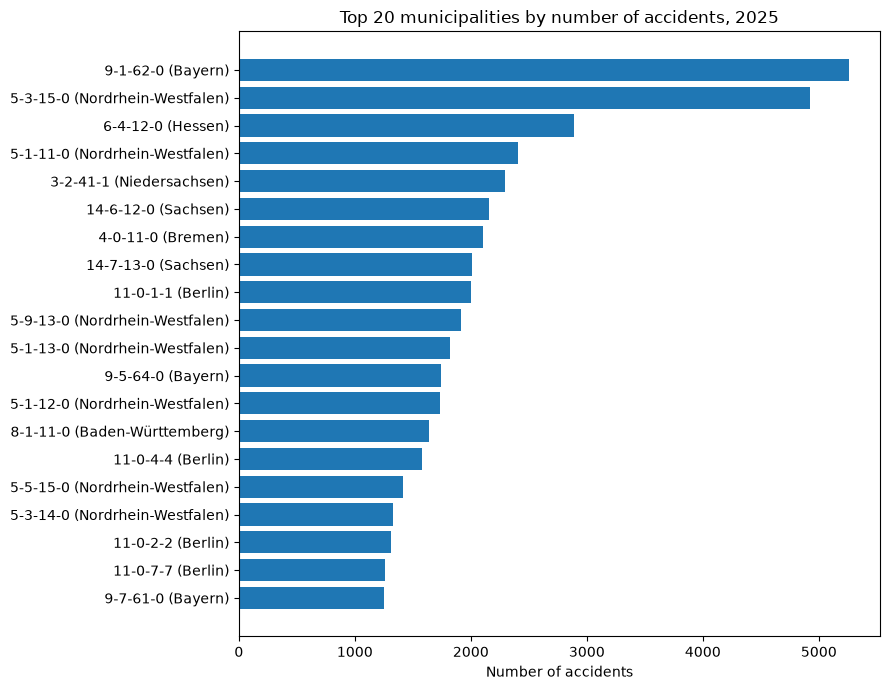

In [56]:
import matplotlib.pyplot as plt

# 1. Overview: how many accidents do municipalities have?
print(unique_municipalities["accidents"].describe().round(1))
print("\nmunicipalities with only 1 accident:", (unique_municipalities["accidents"] == 1).sum())
print("municipalities with 100+ accidents: ", (unique_municipalities["accidents"] >= 100).sum())

# 2. Bar chart: the 20 municipalities with the most accidents
top_20_municipalities = unique_municipalities.head(20).sort_values("accidents")
plt.figure(figsize=(9, 7))
plt.barh(top_20_municipalities["municipality"] + " (" + top_20_municipalities["state_name"] + ")",
         top_20_municipalities["accidents"], color="tab:blue")
plt.xlabel("Number of accidents")
plt.title("Top 20 municipalities by number of accidents, 2025")
plt.tight_layout()
plt.show()

In [57]:
# Look at the raw Excel file first: sheet names and the first rows
municipalities_excel = pd.ExcelFile("data/municipalities_population_31122025.xlsx")
print(municipalities_excel.sheet_names)

municipalities_raw = pd.read_excel(municipalities_excel, sheet_name=1, header=None)
print(municipalities_raw.shape)
municipalities_raw.head(15)

FileNotFoundError: [Errno 2] No such file or directory: 'data/municipalities_population_31122025.xlsx'

In [61]:
# 1. Read the Destatis municipality list (skip 6 title/header lines, read everything as text)
municipality_columns = [
    "record_type", "text_code", "land", "rb", "kreis", "vb", "gem", "municipality_name",
    "area_km2", "population", "population_male", "population_female", "population_per_km2",
    "postcode", "longitude", "latitude", "travel_region_code", "travel_region",
    "urbanisation_code", "urbanisation",
]
municipalities_read = pd.read_excel(
    "data/municipalities_2025.xlsx", sheet_name="Onlineprodukt_Gemeinden31122025",
    header=None, skiprows=6, names=municipality_columns, dtype=str,
)

# 2. Keep only municipality rows (record type 60) and the columns we need
municipalities_population = municipalities_read.loc[
    municipalities_read["record_type"] == "60",
    ["land", "rb", "kreis", "gem", "municipality_name", "area_km2", "population", "population_per_km2", "urbanisation"],
].copy()
municipalities_population["ags"] = (
    municipalities_population["land"] + municipalities_population["rb"]
    + municipalities_population["kreis"] + municipalities_population["gem"]
)
municipalities_population["area_km2"] = municipalities_population["area_km2"].astype(float)
municipalities_population["population"] = municipalities_population["population"].astype(int)
municipalities_population["population_per_km2"] = municipalities_population["population_per_km2"].astype(float)
print("municipalities in Destatis list:", len(municipalities_population))                 # expected: 10953
print("population total:", municipalities_population["population"].sum())                  # expected: 83467117 (same as state table)

# 3. Turn our accident codes into the 8-digit key: "14-6-12-0" -> "14612000"
municipality_keys = unique_municipalities.copy()
code_parts = municipality_keys["municipality"].str.split("-", expand=True)
municipality_keys["ags"] = (
    code_parts[0].str.zfill(2) + code_parts[1] + code_parts[2].str.zfill(2) + code_parts[3].str.zfill(3)
)
municipality_keys.loc[municipality_keys["state"] == 11, "ags"] = "11000000"   # Berlin = one municipality
municipality_keys.loc[municipality_keys["state"] == 2, "ags"] = "02000000"    # Hamburg = one municipality

# 4. Accidents per city with name, population and rate per 1,000 inhabitants
city_accidents = (
    municipality_keys.groupby("ags", as_index=False)["accidents"].sum()
    .merge(municipalities_population[["ags", "municipality_name", "population", "area_km2",
                                      "population_per_km2", "urbanisation"]], on="ags", how="left")
)
city_accidents["accidents_per_1000"] = (city_accidents["accidents"] / city_accidents["population"] * 1000).round(2)
city_accidents = city_accidents.sort_values("accidents", ascending=False).reset_index(drop=True)

print("cities:", len(city_accidents), "| without name:", city_accidents["municipality_name"].isna().sum())   # expected: 9289 | 1
city_accidents.head(20)

municipalities in Destatis list: 10953
population total: 83467117
cities: 9289 | without name: 1


,ags,accidents,municipality_name,population,area_km2,population_per_km2,urbanisation,accidents_per_1000
0,11000000,13280,"Berlin, Stadt",3700577.0,891.12,4153.0,dicht besiedelt,3.59
1,02000000,7057,"Hamburg, Freie und Hansestadt",1869473.0,755.09,2476.0,dicht besiedelt,3.77
2,09162000,5264,"München, Landeshauptstadt",1505036.0,310.70,4844.0,dicht besiedelt,3.50
3,05315000,4922,"Köln, Stadt",1025523.0,405.02,2532.0,dicht besiedelt,4.80
4,06412000,2885,"Frankfurt am Main, Stadt",760656.0,248.31,3063.0,dicht besiedelt,3.79
5,05111000,2407,"Düsseldorf, Stadt",619444.0,217.41,2849.0,dicht besiedelt,3.89
6,03241001,2291,"Hannover, Landeshauptstadt",522803.0,204.30,2559.0,dicht besiedelt,4.38
7,14612000,2154,"Dresden, Stadt",562764.0,328.48,1713.0,dicht besiedelt,3.83
8,04011000,2106,"Bremen, Stadt",588413.0,326.17,1804.0,dicht besiedelt,3.58
9,14713000,2008,"Leipzig, Stadt",615932.0,297.81,2068.0,dicht besiedelt,3.26


In [62]:
# 1. No accident lost? Both totals must be 273007
print("accidents before:", unique_municipalities["accidents"].sum())
print("accidents after: ", city_accidents["accidents"].sum())

# 2. Every original code got a key (no code dropped)
print("codes without key:", municipality_keys["ags"].isna().sum())                       # expected: 0

# 3. How many original codes were merged into Berlin and Hamburg?
print("Berlin codes: ", (municipality_keys["ags"] == "11000000").sum())                  # expected: 12
print("Hamburg codes:", (municipality_keys["ags"] == "02000000").sum())                 # expected: 180

# 4. The one code without a name in the Destatis list
city_accidents[city_accidents["municipality_name"].isna()]

accidents before: 273007
accidents after:  273007
codes without key: 0
Berlin codes:  12
Hamburg codes: 180


,ags,accidents,municipality_name,population,area_km2,population_per_km2,urbanisation,accidents_per_1000
8552,07232089,1,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
city_accidents.to_csv("data/city_accidents_2025.csv", index=False, encoding="utf-8")

# Check: read it back (ags as text, so leading zeros like "02000000" are kept)
saved_city_check = pd.read_csv("data/city_accidents_2025.csv", dtype={"ags": str})
print(saved_city_check.shape)                                    # expected: (9289, 8)
print("accidents total:", saved_city_check["accidents"].sum())   # expected: 273007
saved_city_check.head()

(9289, 8)
accidents total: 273007


,ags,accidents,municipality_name,population,area_km2,population_per_km2,urbanisation,accidents_per_1000
0,11000000,13280,"Berlin, Stadt",3700577.0,891.12,4153.0,dicht besiedelt,3.59
1,02000000,7057,"Hamburg, Freie und Hansestadt",1869473.0,755.09,2476.0,dicht besiedelt,3.77
2,09162000,5264,"München, Landeshauptstadt",1505036.0,310.70,4844.0,dicht besiedelt,3.50
3,05315000,4922,"Köln, Stadt",1025523.0,405.02,2532.0,dicht besiedelt,4.80
4,06412000,2885,"Frankfurt am Main, Stadt",760656.0,248.31,3063.0,dicht besiedelt,3.79


In [64]:
# Load both saved tables
states_saved = pd.read_csv("data/population_states_licence_2025.csv")
cities_saved = pd.read_csv("data/city_accidents_2025.csv", dtype={"ags": str})

# Population per state, summed from ALL municipalities in the Destatis list
population_from_municipalities = (
    municipalities_population.assign(ULAND=municipalities_population["land"].astype(int))
    .groupby("ULAND")["population"].sum().rename("population_municipalities")
)

# Accidents per state from the city table (first 2 digits of ags = state) and from acc_k
accidents_from_cities = (
    cities_saved.assign(ULAND=cities_saved["ags"].str[:2].astype(int))
    .groupby("ULAND")["accidents"].sum().rename("accidents_city_table")
)
accidents_from_acc_k = acc_k.groupby("state").size().rename("accidents_acc_k")

# Side by side, with differences (all should be 0)
state_city_comparison = (
    states_saved.set_index("ULAND")[["state", "total"]]
    .rename(columns={"total": "population_state_table"})
    .join(population_from_municipalities)
    .join(accidents_from_cities)
    .join(accidents_from_acc_k)
)
state_city_comparison["population_diff"] = state_city_comparison["population_state_table"] - state_city_comparison["population_municipalities"]
state_city_comparison["accidents_diff"] = state_city_comparison["accidents_acc_k"] - state_city_comparison["accidents_city_table"]

print(state_city_comparison[["population_diff", "accidents_diff"]].abs().sum())   # expected: 0 and 0
state_city_comparison

population_diff    0
accidents_diff     0
dtype: int64


,state,population_state_table,population_municipalities,accidents_city_table,accidents_acc_k,population_diff,accidents_diff
ULAND,,,,,,,
1,Schleswig-Holstein,2958519,2958519,11645,11645,0,0
2,Hamburg,1869473,1869473,7057,7057,0,0
3,Niedersachsen,8000826,8000826,24556,24556,0,0
4,Bremen,706915,706915,2575,2575,0,0
5,Nordrhein-Westfalen,17986214,17986214,61521,61521,0,0
6,Hessen,6278594,6278594,18578,18578,0,0
7,Rheinland-Pfalz,4123022,4123022,12816,12816,0,0
8,Baden-Württemberg,11238761,11238761,32042,32042,0,0
9,Bayern,13245503,13245503,46938,46938,0,0


In [65]:
# 1. Unique cities directly from acc_k (same key rule: Berlin and Hamburg = one city)
acc_k_cities = acc_k[["state", "municipality"]].copy()
acc_k_parts = acc_k_cities["municipality"].str.split("-", expand=True)
acc_k_cities["ags"] = (
    acc_k_parts[0].str.zfill(2) + acc_k_parts[1] + acc_k_parts[2].str.zfill(2) + acc_k_parts[3].str.zfill(3)
)
acc_k_cities.loc[acc_k_cities["state"] == 11, "ags"] = "11000000"
acc_k_cities.loc[acc_k_cities["state"] == 2, "ags"] = "02000000"
acc_k_city_counts = acc_k_cities.groupby("ags").size().rename("accidents_acc_k")

# 2. The saved city table
city_file = pd.read_csv("data/city_accidents_2025.csv", dtype={"ags": str}).set_index("ags")

# 3. Same cities in both?
print("unique cities in acc_k:      ", acc_k_city_counts.index.nunique())   # expected: 9289
print("cities in city_accidents.csv:", city_file.index.nunique())          # expected: 9289
print("in acc_k but not in file:", len(set(acc_k_city_counts.index) - set(city_file.index)))   # expected: 0
print("in file but not in acc_k:", len(set(city_file.index) - set(acc_k_city_counts.index)))   # expected: 0

# 4. Same number of accidents in every city?
city_compare = city_file[["municipality_name", "accidents"]].join(acc_k_city_counts)
city_compare["difference"] = city_compare["accidents"] - city_compare["accidents_acc_k"]
print("cities with different accident count:", (city_compare["difference"] != 0).sum())       # expected: 0

city_compare.head(10)

unique cities in acc_k:       9289
cities in city_accidents.csv: 9289
in acc_k but not in file: 0
in file but not in acc_k: 0
cities with different accident count: 0


,municipality_name,accidents,accidents_acc_k,difference
ags,,,,
11000000,"Berlin, Stadt",13280,13280,0
02000000,"Hamburg, Freie und Hansestadt",7057,7057,0
09162000,"München, Landeshauptstadt",5264,5264,0
05315000,"Köln, Stadt",4922,4922,0
06412000,"Frankfurt am Main, Stadt",2885,2885,0
05111000,"Düsseldorf, Stadt",2407,2407,0
03241001,"Hannover, Landeshauptstadt",2291,2291,0
14612000,"Dresden, Stadt",2154,2154,0
04011000,"Bremen, Stadt",2106,2106,0


In [66]:
# Load the original accident data from the data folder
accidents_original = pd.read_csv(
    "data/Unfallorte_2025.csv",
    sep=";",                          # German CSV: semicolon as separator
    decimal=",",                      # German decimal comma in the coordinates
    dtype={"UIDENTSTLAE": str},       # keep the accident ID as text (leading zeros)
)

print(accidents_original.shape)       # expected: (273007, 25)
accidents_original.head()

(273007, 25)


,UIDENTSTLAE,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UJAHR,UMONAT,USTUNDE,UWOCHENTAG,UKATEGORIE,...,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstige,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84,PLST
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,...,1,0,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,...,0,0,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,...,1,0,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,...,1,1,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,...,0,0,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1


In [67]:
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check,killed
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok,0
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok,0
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok,0
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok,0
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok,0


In [68]:
from pathlib import Path

# Create the folder data/processed (no error if it already exists)
processed_folder = Path("data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

# Save acc_k there
acc_k.to_csv(processed_folder / "accidents_2025.csv", index=False, encoding="utf-8")

# Check: read it back (ID as text, so leading zeros are kept)
accidents_2025_check = pd.read_csv(processed_folder / "accidents_2025.csv", dtype={"accident_id": str})
print(accidents_2025_check.shape)   # expected: (273007, 36)
accidents_2025_check.head()

(273007, 36)


,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check,killed
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok,0
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok,0
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok,0
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok,0
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok,0


In [69]:
# Unique municipality codes, as they are in the data
print("unique municipality codes:", accidents_2025_check["municipality"].nunique())   # 9479

# Real cities: count Berlin (state 11) and Hamburg (state 2) as one city each
real_cities = accidents_2025_check["municipality"].where(
    ~accidents_2025_check["state"].isin([2, 11]),
    accidents_2025_check["state"].astype(str),        # all Berlin codes -> "11", all Hamburg codes -> "2"
)
print("unique real cities:       ", real_cities.nunique())                             # 9289

unique municipality codes: 9479
unique real cities:        9289


In [70]:
# 1. Load both saved files (keys as text, so leading zeros are kept)
accidents_file = pd.read_csv("data/processed/accidents_2025.csv", dtype={"accident_id": str})
cities_file = pd.read_csv("data/city_accidents_2025.csv", dtype={"ags": str})

# 2. Build the 8-digit city key for every accident ("14-6-12-0" -> "14612000"; Berlin and Hamburg = one city)
key_parts = accidents_file["municipality"].str.split("-", expand=True)
accidents_file["ags"] = key_parts[0].str.zfill(2) + key_parts[1] + key_parts[2].str.zfill(2) + key_parts[3].str.zfill(3)
accidents_file.loc[accidents_file["state"] == 11, "ags"] = "11000000"
accidents_file.loc[accidents_file["state"] == 2, "ags"] = "02000000"

# 3. Same cities in both files?
cities_in_accidents = set(accidents_file["ags"])
cities_in_city_file = set(cities_file["ags"])
print("cities in accidents_2025:     ", len(cities_in_accidents))                       # 9289
print("cities in city_accidents_2025:", len(cities_in_city_file))                       # 9289
print("only in accidents_2025:       ", len(cities_in_accidents - cities_in_city_file))  # 0
print("only in city_accidents_2025:  ", len(cities_in_city_file - cities_in_accidents))  # 0

# 4. Same number of accidents in every city?
accidents_per_city_check = accidents_file.groupby("ags").size().rename("accidents_from_accidents_file")
city_check_table = cities_file.set_index("ags")[["municipality_name", "accidents"]].join(accidents_per_city_check)
print("cities with different count:  ", (city_check_table["accidents"] != city_check_table["accidents_from_accidents_file"]).sum())  # 0

cities in accidents_2025:      9289
cities in city_accidents_2025: 9289
only in accidents_2025:        0
only in city_accidents_2025:   0
cities with different count:   0


In [73]:
cities_file = pd.read_csv("data/city_accidents_2025.csv", dtype={"ags": str})
print(cities_file.dtypes)
cities_file.head()

ags                       str
accidents               int64
municipality_name         str
population            float64
area_km2              float64
population_per_km2    float64
urbanisation              str
accidents_per_1000    float64
dtype: object


,ags,accidents,municipality_name,population,area_km2,population_per_km2,urbanisation,accidents_per_1000
0,11000000,13280,"Berlin, Stadt",3700577.0,891.12,4153.0,dicht besiedelt,3.59
1,02000000,7057,"Hamburg, Freie und Hansestadt",1869473.0,755.09,2476.0,dicht besiedelt,3.77
2,09162000,5264,"München, Landeshauptstadt",1505036.0,310.70,4844.0,dicht besiedelt,3.50
3,05315000,4922,"Köln, Stadt",1025523.0,405.02,2532.0,dicht besiedelt,4.80
4,06412000,2885,"Frankfurt am Main, Stadt",760656.0,248.31,3063.0,dicht besiedelt,3.79


In [74]:
# 1. Copy of the accidents with the city key (ags), so accidents_file stays unchanged
accidents_with_city = accidents_file.copy()

# 2. Check: does every accident's city exist in the city table?
city_match = accidents_with_city["ags"].isin(cities_file["ags"])
print("accidents with matching city:   ", city_match.sum())        # expected: 273007
print("accidents without matching city:", (~city_match).sum())     # expected: 0

# 3. Only if all cities match: add the three city columns
if city_match.all():
    accidents_with_city = accidents_with_city.merge(
        cities_file[["ags", "population", "area_km2", "population_per_km2"]],
        on="ags",
        how="left",
        validate="many_to_one",   # safety check: each city only once in the city table
    )
    print("columns added. shape:", accidents_with_city.shape)      # expected: (273007, 40)
else:
    print("Not all cities match: nothing was added.")

accidents_with_city[["accident_id", "municipality", "ags", "population", "area_km2", "population_per_km2"]].head()

accidents with matching city:    273007
accidents without matching city: 0
columns added. shape: (273007, 40)


,accident_id,municipality,ags,population,area_km2,population_per_km2
0,01250509171013352025,1-0-60-7,01060007,1067.0,34.85,31.0
1,01250405161013752025,1-0-62-53,01062053,9052.0,11.36,797.0
2,01250118171013142025,1-0-56-15,01056015,51375.0,21.36,2405.0
3,01250326152013912025,1-0-55-28,01055028,10842.0,69.07,157.0
4,01250225145013362025,1-0-58-116,01058116,834.0,13.89,60.0


In [75]:
# Save the accidents with the new city columns into the same file
accidents_with_city.to_csv("data/processed/accidents_2025.csv", index=False, encoding="utf-8")

# Check: read it back (ID and ags as text, so leading zeros are kept)
accidents_2025_updated = pd.read_csv(
    "data/processed/accidents_2025.csv", dtype={"accident_id": str, "ags": str}
)
print(accidents_2025_updated.shape)   # expected: (273007, 40)
print(accidents_2025_updated.columns[-4:].tolist())   # expected: ['ags', 'population', 'area_km2', 'population_per_km2']

(273007, 40)
['ags', 'population', 'area_km2', 'population_per_km2']


In [76]:
accidents_2025_updated.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check,killed,ags,population,area_km2,population_per_km2
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,0,1,0,2025-05-09,ok,0,01060007,1067.0,34.85,31.0
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,1,1,0,2025-04-05,ok,0,01062053,9052.0,11.36,797.0
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,0,1,0,2025-01-18,ok,0,01056015,51375.0,21.36,2405.0
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,1,0,1,2025-03-26,ok,0,01055028,10842.0,69.07,157.0
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,1,1,0,2025-02-25,ok,0,01058116,834.0,13.89,60.0


In [77]:
print(accidents_2025_updated.shape)                    # (273007, 40) = saved with the new columns
print(accidents_2025_updated.columns[-4:].tolist())    # ['ags', 'population', 'area_km2', 'population_per_km2']

(273007, 40)
['ags', 'population', 'area_km2', 'population_per_km2']


In [78]:
# Load the updated file from disk and show it
accidents_2025_final = pd.read_csv(
    "data/processed/accidents_2025.csv", dtype={"accident_id": str, "ags": str}
)
pd.set_option("display.max_columns", None)   # show all 40 columns, no "..."

print(accidents_2025_final.shape)            # expected: (273007, 40)
accidents_2025_final.head()

(273007, 40)


,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,accident_kind,accident_type,light,road_condition,bicycle,car,pedestrian,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check,killed,ags,population,area_km2,population_per_km2
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,Collision with another vehicle which turns int...,Accident caused by turning into a road or by c...,daylight,dry,0,1,0,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,0,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok,0,01060007,1067.0,34.85,31.0
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,Accident of another kind,Other accident,daylight,dry,1,0,0,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok,0,01062053,9052.0,11.36,797.0
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,Collision with another vehicle which turns int...,Accident caused by turning into a road or by c...,daylight,wet/damp/slippery,0,1,0,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,0,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok,0,01056015,51375.0,21.36,2405.0
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,Collision between vehicle and pedestrian,Accident caused by turning off the road,daylight,dry,0,1,1,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok,0,01055028,10842.0,69.07,157.0
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,Collision with another vehicle moving ahead or...,Accident between vehicles moving along in carr...,daylight,dry,1,0,0,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok,0,01058116,834.0,13.89,60.0


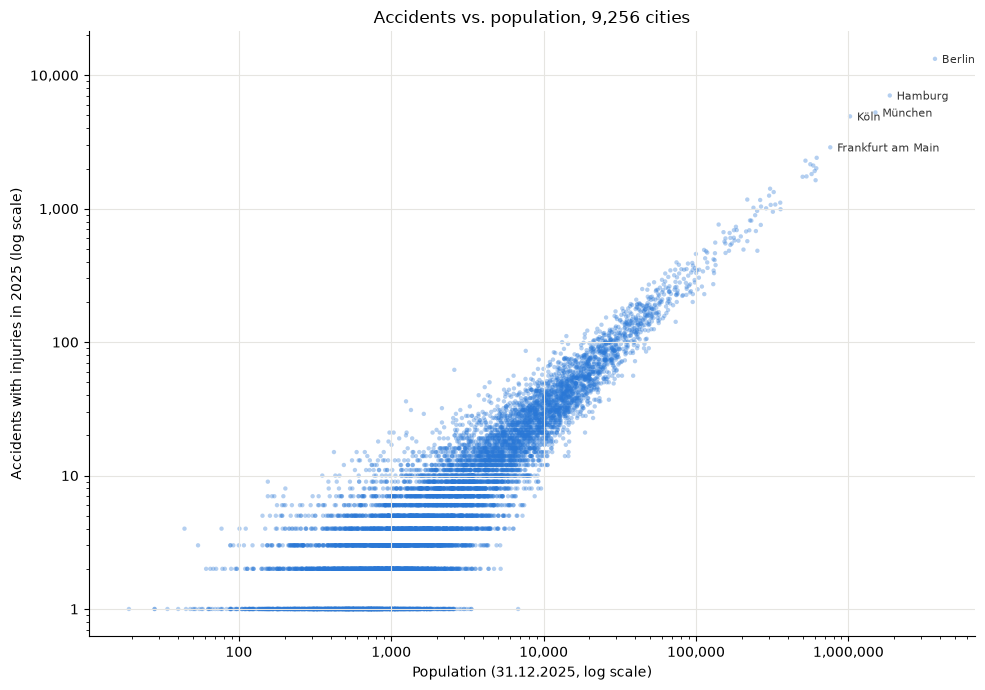

            population  accidents
population        1.00       0.89
accidents         0.89       1.00


In [79]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1. One row per city: number of accidents + population (from the updated accidents file)
city_plot_data = (
    accidents_2025_final.groupby("ags")
    .agg(accidents=("ags", "size"), population=("population", "first"))
    .dropna(subset=["population"])                      # 1 city without population (07232089)
)
city_plot_data = city_plot_data[city_plot_data["population"] > 0]   # log scale cannot show 0

# City names from the city table, for labelling the biggest cities
city_names = cities_file.set_index("ags")["municipality_name"]
city_plot_data["city"] = city_names.reindex(city_plot_data.index).str.split(",").str[0]   # "Köln, Stadt" -> "Köln"

# 2. Scatter plot: one dot per city
thousands = FuncFormatter(lambda value, _: f"{value:,.0f}")
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(city_plot_data["population"], city_plot_data["accidents"],
           s=10, color="#2a78d6", alpha=0.35, edgecolors="none")

# Label the 5 biggest cities
for _, row in city_plot_data.nlargest(5, "population").iterrows():
    ax.annotate(row["city"], (row["population"], row["accidents"]),
                xytext=(5, -3), textcoords="offset points", fontsize=8, color="#333333")

ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("Population (31.12.2025, log scale)")
ax.set_ylabel("Accidents with injuries in 2025 (log scale)")
ax.set_title(f"Accidents vs. population, {len(city_plot_data):,} cities")
ax.grid(True, color="#e6e5e1", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# How strongly are they related? (Spearman: 1 = perfect)
print(city_plot_data[["population", "accidents"]].corr(method="spearman").round(2))

In [80]:
# Work on a copy, so accidents_2025_final stays unchanged
accidents_2025_marked = accidents_2025_final.copy()

# Mark the special cases
accidents_2025_marked["city_note"] = "ok"
accidents_2025_marked.loc[accidents_2025_marked["population"] == 0, "city_note"] = "uninhabited_area"
accidents_2025_marked.loc[accidents_2025_marked["population"].isna(), "city_note"] = "no_city_data"

# Check the counts
print(accidents_2025_marked["city_note"].value_counts())
# expected: ok 272812 | uninhabited_area 194 | no_city_data 1

# Save into the processed file (now 41 columns)
accidents_2025_marked.to_csv("data/processed/accidents_2025.csv", index=False, encoding="utf-8")
print(accidents_2025_marked.shape)   # expected: (273007, 41)

city_note
ok                  272812
uninhabited_area       194
no_city_data             1
Name: count, dtype: int64
(273007, 41)


severe share in special areas: 31.8% | all accidents: 15.7%


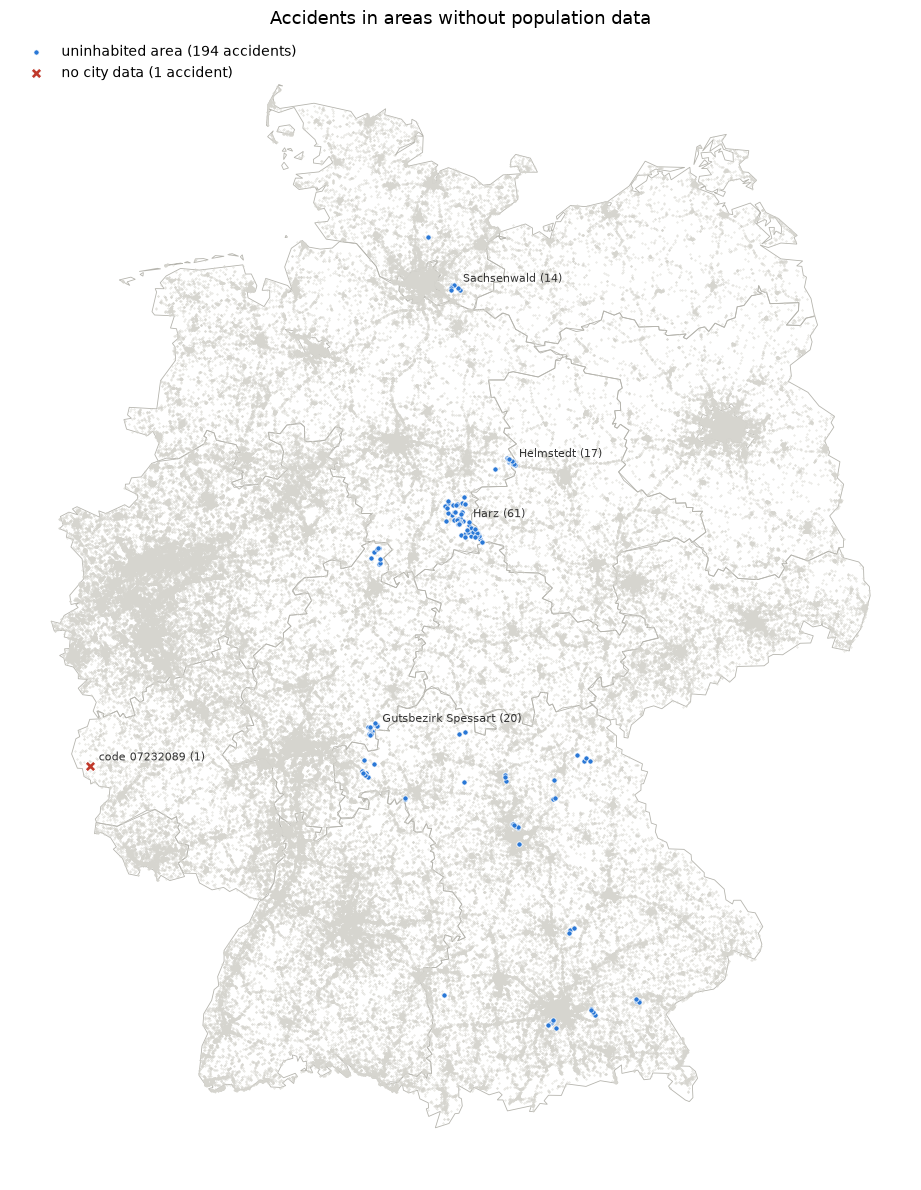

,ags,municipality_name,state_name,city_note,accidents,killed,seriously_injured,area_km2
0,03153504,"Harz (Landkreis Goslar), gemfr. Gebiet",Niedersachsen,uninhabited_area,61,1,21,372.34
1,06435200,"Gutsbezirk Spessart, gemfr. Gebiet",Hessen,uninhabited_area,20,0,9,89.29
2,03154502,"Helmstedt, gemfr. Gebiet",Niedersachsen,uninhabited_area,17,0,5,18.73
3,01053105,"Sachsenwald (Forstgutsbez.),gemfr.Geb.",Schleswig-Holstein,uninhabited_area,14,0,3,58.49
4,09184452,Forstenrieder Park,Bayern,uninhabited_area,13,0,5,37.09
5,09572460,Neunhofer Forst,Bayern,uninhabited_area,9,0,2,10.17
6,06633200,"Gutsbezirk Reinhardswald, gemfr. Gebiet",Hessen,uninhabited_area,8,1,2,182.50
7,09671456,Rohrbrunner Forst,Bayern,uninhabited_area,7,0,1,33.36
8,09183451,Mühldorfer Hart,Bayern,uninhabited_area,6,0,3,7.12
9,09471455,Hauptsmoor,Bayern,uninhabited_area,4,0,0,20.84


In [81]:
import json, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# 1. Coordinates and severity of every accident from the original file (joined on the accident ID)
original_coordinates = pd.read_csv(
    "data/Unfallorte_2025.csv", sep=";", decimal=",", dtype={"UIDENTSTLAE": str},
    usecols=["UIDENTSTLAE", "UKATEGORIE", "XGCSWGS84", "YGCSWGS84"],
).rename(columns={"UIDENTSTLAE": "accident_id", "XGCSWGS84": "lon", "YGCSWGS84": "lat"})
accidents_on_map = accidents_2025_marked.merge(original_coordinates, on="accident_id", how="left")
special_accidents = accidents_on_map[accidents_on_map["city_note"] != "ok"]

# 2. Table: one row per special area, with state, accidents, killed, seriously injured, area
special_areas = (
    special_accidents.groupby(["ags", "city_note", "state_name"])
    .agg(accidents=("accident_id", "size"),
         killed=("UKATEGORIE", lambda s: (s == 1).sum()),
         seriously_injured=("UKATEGORIE", lambda s: (s == 2).sum()),
         area_km2=("area_km2", "first"),
         lon=("lon", "mean"), lat=("lat", "mean"))
    .reset_index()
    .merge(cities_file[["ags", "municipality_name"]], on="ags", how="left")
    .sort_values("accidents", ascending=False)
    .reset_index(drop=True)
)
severe_share_special = (special_areas["killed"].sum() + special_areas["seriously_injured"].sum()) / special_areas["accidents"].sum()
print(f"severe share in special areas: {severe_share_special:.1%} | all accidents: {(accidents_on_map['UKATEGORIE'] <= 2).mean():.1%}")

# 3. Map: state borders, all accidents in grey, special cases on top
GERMANY_STATES_URL = "https://raw.githubusercontent.com/isellsoap/deutschlandGeoJSON/main/2_bundeslaender/4_niedrig.geo.json"
with urllib.request.urlopen(GERMANY_STATES_URL) as response:
    germany_states_geojson = json.load(response)

fig, ax = plt.subplots(figsize=(10, 12))
for feature in germany_states_geojson["features"]:
    geometry = feature["geometry"]
    parts = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    for part in parts:
        ax.add_patch(Polygon(np.array(part[0]), facecolor="none", edgecolor="#b5b4ad", linewidth=0.6))

ax.scatter(accidents_on_map["lon"], accidents_on_map["lat"], s=0.1, color="#d6d5cf", rasterized=True)
uninhabited = special_accidents[special_accidents["city_note"] == "uninhabited_area"]
no_data = special_accidents[special_accidents["city_note"] == "no_city_data"]
ax.scatter(uninhabited["lon"], uninhabited["lat"], s=14, color="#2a78d6", edgecolors="white", linewidths=0.5,
           label=f"uninhabited area ({len(uninhabited)} accidents)")
ax.scatter(no_data["lon"], no_data["lat"], s=60, marker="X", color="#c0392b", edgecolors="white", linewidths=0.8,
           label=f"no city data ({len(no_data)} accident)")

# Label the 4 areas with most accidents and the missing city
for _, row in pd.concat([special_areas.head(4), special_areas[special_areas["city_note"] == "no_city_data"]]).iterrows():
    label = row["municipality_name"].split(",")[0].split(" (")[0] if isinstance(row["municipality_name"], str) else f"code {row['ags']}"
    ax.annotate(f"{label} ({row['accidents']})", (row["lon"], row["lat"]), xytext=(6, 4),
                textcoords="offset points", fontsize=8, color="#333333")

ax.set_title("Accidents in areas without population data", fontsize=13)
ax.legend(loc="upper left", frameon=False)
ax.set_aspect(1.5)
ax.set_axis_off()
plt.tight_layout()
plt.show()

special_areas[["ags", "municipality_name", "state_name", "city_note", "accidents", "killed", "seriously_injured", "area_km2"]]

In [82]:
# Work on a copy, so accidents_2025_marked stays unchanged
accidents_2025_clean = accidents_2025_marked.copy()

# Set the city columns to NaN for the special cases (rows are kept)
city_columns = ["population", "area_km2", "population_per_km2"]
is_special = accidents_2025_clean["city_note"] != "ok"
accidents_2025_clean.loc[is_special, city_columns] = np.nan

# Check
print(accidents_2025_clean[city_columns].isna().sum())   # expected: 195 in each column (194 + 1)
print(accidents_2025_clean.shape)                        # expected: (273007, 41), no new columns

# Save into the processed file
accidents_2025_clean.to_csv("data/processed/accidents_2025.csv", index=False, encoding="utf-8")

population            195
area_km2              195
population_per_km2    195
dtype: int64
(273007, 41)


In [83]:
# Load the saved file from disk
accidents_2025_saved = pd.read_csv(
    "data/processed/accidents_2025.csv", dtype={"accident_id": str, "ags": str}
)
pd.set_option("display.max_columns", None)   # show all columns

# Was the update saved?
print(accidents_2025_saved.shape)                                         # expected: (273007, 41)
print(accidents_2025_saved["city_note"].value_counts())                   # ok 272812 | uninhabited_area 194 | no_city_data 1
print("NaN in population:", accidents_2025_saved["population"].isna().sum())   # expected: 195

accidents_2025_saved.head()

(273007, 41)
city_note
ok                  272812
uninhabited_area       194
no_city_data             1
Name: count, dtype: int64
NaN in population: 195


,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,accident_kind,accident_type,light,road_condition,bicycle,car,pedestrian,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check,killed,ags,population,area_km2,population_per_km2,city_note
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,Collision with another vehicle which turns int...,Accident caused by turning into a road or by c...,daylight,dry,0,1,0,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,0,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok,0,01060007,1067.0,34.85,31.0,ok
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,Accident of another kind,Other accident,daylight,dry,1,0,0,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok,0,01062053,9052.0,11.36,797.0,ok
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,Collision with another vehicle which turns int...,Accident caused by turning into a road or by c...,daylight,wet/damp/slippery,0,1,0,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,0,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok,0,01056015,51375.0,21.36,2405.0,ok
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,Collision between vehicle and pedestrian,Accident caused by turning off the road,daylight,dry,0,1,1,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok,0,01055028,10842.0,69.07,157.0,ok
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,Collision with another vehicle moving ahead or...,Accident between vehicles moving along in carr...,daylight,dry,1,0,0,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok,0,01058116,834.0,13.89,60.0,ok


In [84]:
print(accidents_2025_saved[["ags", "population", "area_km2", "population_per_km2", "city_note"]].isna().sum())

ags                     0
population            195
area_km2              195
population_per_km2    195
city_note               0
dtype: int64


In [85]:
print(accidents_2025_saved["city_note"].value_counts())
print("not ok:", (accidents_2025_saved["city_note"] != "ok").sum())   # expected: 195

city_note
ok                  272812
uninhabited_area       194
no_city_data             1
Name: count, dtype: int64
not ok: 195


## Update: city data added (21.10.2026)

**Updated dataset:** `data/processed/accidents_2025.csv`: 273,007 accidents, 41 columns

**What we did**
1. Loaded the Destatis list of all German cities (`data/municipalities_2025.xlsx`, 31.12.2025) with name, population and area.
2. Gave every accident the official city key `ags`, built from its own location codes (e.g. `14-6-12-0` → `14612000` = Dresden). Berlin and Hamburg are split into many small areas in the accident data, so we count each of them as one city.
3. Saved a table with one row per city: `data/city_accidents_2025.csv` (9,289 cities, with name and number of accidents).
4. Checked: both files have the same cities and the same number of accidents per city.
5. Added 3 new columns to the accidents: `population`, `area_km2` and `population_per_km2` of the city where the accident happened (e.g. all 2,154 accidents in Dresden have population = 562,764).
6. Added `city_note` to mark special cases.

**Special cases (`city_note`)**

| `city_note` | Accidents | Reason | population, area_km2, population_per_km2 |
|---|---|---|---|
| `ok` | 272,812 | normal city | real values |
| `uninhabited_area` | 194 | area without inhabitants (forests, e.g. Harz, Spessart) | NaN |
| `no_city_data` | 1 | outdated code `07232089` (Niedergeckler, merged into Obergeckler on 01.01.2025) | NaN |

**Notes**
* Load with `dtype={"accident_id": str, "ags": str}`, so the leading zeros stay (Hamburg = `02000000`).
* The 195 rows with NaN are kept; handle them before training (fill or drop).

Sources: [Destatis, Gemeindeverzeichnis 31.12.2025](https://www.destatis.de/DE/Themen/Laender-Regionen/Regionales/Gemeindeverzeichnis/Administrativ/Archiv/GVAuszugJ/31122025_Auszug_GV.html) · [Wikipedia, VG Südeifel (merger Niedergeckler)](https://de.wikipedia.org/wiki/Verbandsgemeinde_S%C3%BCdeifel)

In [86]:
# Keep only accidents with population data (drop the 195 special cases)
accidents_2025_with_population = accidents_2025_saved[accidents_2025_saved["city_note"] == "ok"].copy()

# Check
print("before:", len(accidents_2025_saved))                                       # 273007
print("after: ", len(accidents_2025_with_population))                             # 272812
print("dropped:", len(accidents_2025_saved) - len(accidents_2025_with_population))  # 195
print("NaN left in population:", accidents_2025_with_population["population"].isna().sum())   # 0

# Save as a new file in the data folder
accidents_2025_with_population.to_csv(
    "data/accidents_2025_with_population.csv", index=False, encoding="utf-8"
)
print(accidents_2025_with_population.shape)   # expected: (272812, 41)

before: 273007
after:  272812
dropped: 195
NaN left in population: 0
(272812, 41)


In [87]:
accidents_2025_with_population.info()

<class 'pandas.DataFrame'>
Index: 272812 entries, 0 to 273006
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   accident_id            272812 non-null  str    
 1   state                  272812 non-null  int64  
 2   region                 272812 non-null  str    
 3   district               272812 non-null  str    
 4   municipality           272812 non-null  str    
 5   year                   272812 non-null  int64  
 6   month                  272812 non-null  int64  
 7   hour                   272812 non-null  int64  
 8   weekday                272812 non-null  str    
 9   severity               272812 non-null  str    
 10  accident_kind          272812 non-null  str    
 11  accident_type          272812 non-null  str    
 12  light                  272812 non-null  str    
 13  road_condition         272812 non-null  str    
 14  bicycle                272812 non-null  int64  
 15 

## New dataset: accidents with population data

**File:** `data/accidents_2025_with_population.csv`: 272,812 accidents, 41 columns

**What I did:** removed the 195 accidents without population data from `data/processed/accidents_2025.csv` (194 in uninhabited forest areas + 1 with an outdated city code).

**Result:** every accident has `population`, `area_km2` and `population_per_km2` of its city, with no missing values.